# 🚢 Introducción a Machine Learning: Predicción de supervivencia del Titanic

En este notebook vamos a dar nuestros primeros pasos en **Machine Learning (ML)** utilizando uno de los conjuntos de datos más conocidos del mundo de la ciencia de datos: el desafío **Titanic - Machine Learning from Disaster**, disponible en Kaggle.

El objetivo será construir un modelo capaz de predecir si un pasajero sobrevivió o no al hundimiento del Titanic, utilizando información como su edad, sexo, clase del billete o lugar de embarque.

A lo largo del ejercicio aprenderemos a explorar datos, prepararlos para entrenar modelos de Machine Learning y evaluar los resultados obtenidos.

**Dataset y competición:** [Titanic - Machine Learning from Disaster (Kaggle)](https://www.kaggle.com/competitions/titanic)

---

**Nuestro objetivo:** construir y comparar diferentes modelos de clasificación para intentar predecir correctamente la supervivencia de los pasajeros.

<div align="center">
  <img src="https://maritimecyprus.files.wordpress.com/2015/03/titanic-1.jpg" width="500">
  <p><em>RMS Titanic, fotografiado antes de su hundimiento en abril de 1912.</em></p>
</div>

## Introducción al problema

El 15 de abril de 1912, el RMS Titanic se hundió en el océano Atlántico durante su viaje inaugural, tras chocar contra un iceberg. De las más de 2.200 personas que viajaban a bordo, aproximadamente 1.500 perdieron la vida.

Más de un siglo después, este acontecimiento nos sirve como punto de partida para nuestro primer ejercicio de **Machine Learning**.

Vamos a trabajar con información real de los pasajeros del Titanic para intentar descubrir qué características pudieron influir en sus posibilidades de supervivencia.

### ¿Cuál es nuestro objetivo?

Nuestro objetivo es construir un modelo de Machine Learning capaz de **predecir si un pasajero sobrevivió o no al hundimiento del Titanic** a partir de sus características personales.

Para ello, utilizaremos información como:

- **Edad:** edad del pasajero.
- **Sexo:** hombre o mujer.
- **Clase del billete:** primera, segunda o tercera clase.
- **Número de familiares:** familiares que viajaban con el pasajero.
- **Lugar de embarque:** puerto desde el que subió al barco.

El modelo aprenderá a partir de los datos de pasajeros cuyo resultado conocemos y posteriormente intentará realizar predicciones sobre otros pasajeros.

Este es un problema de **clasificación supervisada**, ya que conocemos los resultados de los ejemplos utilizados para entrenar el modelo y queremos predecir una categoría: sobrevivió o no sobrevivió.


### ¿Con qué información contamos?

Kaggle nos proporciona dos conjuntos de datos:

| Dataset | Descripción |
|---|---|
| `train.csv` | Contiene información de los pasajeros y si sobrevivieron o no. Lo utilizaremos para entrenar y evaluar nuestros modelos. |
| `test.csv` | Contiene información de otros pasajeros, pero no conocemos su resultado de supervivencia. Lo utilizaremos para realizar predicciones. |

A lo largo del notebook seguiremos un flujo de trabajo habitual en Machine Learning:

1. **Exploración:** conocer los datos y entender qué información contienen.
2. **Preparación:** tratar valores ausentes y transformar las variables para que puedan utilizarse en los modelos.
3. **Entrenamiento:** construir modelos capaces de aprender patrones a partir de los datos.
4. **Evaluación y comparación:** medir su rendimiento y comparar los resultados obtenidos.

¡Vamos a empezar!

## Carga de los datasets de Kaggle

In [5]:
import pandas as pd 

# Cargar los conjuntos de datos 
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')

print("Datasets cargados correctamente.")

# Mostrar las dimensiones de los conjuntos de datos cargados
print(f"Train: {train.shape[0]} filas y {train.shape[1]} columnas")
print(f"Test: {test.shape[0]} filas y {test.shape[1]} columnas")

Datasets cargados correctamente.
Train: 891 filas y 12 columnas
Test: 418 filas y 11 columnas


## Exploración de los datos (EDA)

Antes de construir cualquier modelo de Machine Learning, es importante conocer los datos con los que vamos a trabajar. Para ello, realizaremos un proceso conocido como **EDA (Exploratory Data Analysis)**, que significa *Análisis Exploratorio de Datos*.

El EDA consiste en examinar y analizar un conjunto de datos para comprender su estructura, identificar patrones, detectar posibles problemas y obtener información relevante antes de comenzar a trabajar con modelos predictivos.

Durante esta fase intentaremos responder a preguntas como:

- ¿Cuántos pasajeros tenemos y qué información contiene el dataset?
- ¿Qué tipo de variables tenemos: numéricas, categóricas, etc.?
- ¿Existen valores ausentes o datos incompletos?
- ¿Cómo se distribuyen las distintas características de los pasajeros?
- ¿Podemos encontrar relaciones interesantes entre las variables y la supervivencia?

Para ello utilizaremos principalmente **Pandas**, para manipular y analizar los datos, y **Matplotlib** y **Seaborn**, para generar visualizaciones.

**El objetivo no es entrenar todavía ningún modelo, sino entender bien los datos antes de utilizarlos.**


In [12]:
# Mostrar las dimensiones del conjunto de train
print("Número de columnas en train:", train.shape[1])
print("Número de filas en train:", train.shape[0])

# Mostrar las primeras filas del conjunto de train
train.head(5)

Número de columnas en train: 12
Número de filas en train: 891


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [14]:
# En lugar de head, podemos usar sample para obtener una muestra aleatoria de filas del conjunto de datos
train.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.7500,NaN,Q
47,48,1,3,"O'Driscoll, Miss. Bridget",female,NaN,0,0,14311,7.7500,NaN,Q
582,583,0,2,"Downton, Mr. William James",male,54.0,0,0,28403,26.0000,NaN,S
662,663,0,1,"Colley, Mr. Edward Pomeroy",male,47.0,0,0,5727,25.5875,E58,S
857,858,1,1,"Daly, Mr. Peter Denis",male,51.0,0,0,113055,26.5500,E17,S



### Descripción de las variables

Antes de comenzar a explorar el dataset, vamos a conocer qué información contiene cada una de sus variables.

| **Variable** | **Descripción** | **Valores / Significado** |
|:---|:---|:---|
| `PassengerId` | Identificador único del pasajero | 1-891 |
| `Survived` | Supervivencia del pasajero | 0 = No sobrevivió, 1 = Sobrevivió |
| `Pclass` | Clase del billete | 1 = Primera clase, 2 = Segunda clase, 3 = Tercera clase |
| `Sex` | Sexo del pasajero | male = Hombre, female = Mujer |
| `Age` | Edad del pasajero | Edad en años |
| `Sibsp` | Número de hermanos/as y cónyuges a bordo |  |
| `Parch` | Número de padres/madres e hijos/as a bordo |  |
| `Ticket` | Número del billete | Identificador del billete |
| `Fare` | Tarifa del billete | Precio pagado por el pasajero |
| `Cabin` | Número de camarote | Identificador del camarote |
| `Embarked` | Puerto de embarque | C = Cherbourg, Q = Queenstown, S = Southampton |

**Nota:** La variable `Survived` será nuestra variable objetivo (*target*), es decir, aquello que queremos predecir mediante los modelos de Machine Learning.


>Nota: Como debe ser, en el dataset de test no aparece la variable objetivo

In [15]:
# Mostrar las dimensiones del conjunto de test
print("Número de columnas en test:", test.shape[1])
print("Número de filas en test:", test.shape[0])

# Mostrar las primeras filas del conjunto de test
test.head()

Número de columnas en test: 11
Número de filas en test: 418


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


### Análisis de valores faltantes

Antes de continuar, es importante comprobar si nuestro conjunto de datos contiene información incompleta.

Los valores faltantes (*missing values*) son aquellos registros en los que no disponemos de información para una determinada variable.

Su presencia puede afectar al análisis y al entrenamiento de los modelos, por lo que debemos identificarlos y conocer su distribución antes de decidir cómo tratarlos.

En primer lugar, calcularemos el número y el porcentaje de valores faltantes en cada columna.

In [25]:
# Calcular el número y porcentaje de valores faltantes
missing = pd.DataFrame({
    'Valores faltantes': train.isnull().sum(),
    'Porcentaje (%)': train.isnull().mean() * 100
})

# Mostrar únicamente las columnas que contienen valores faltantes
missing = missing[missing['Valores faltantes'] > 0]

missing.sort_values(by='Porcentaje (%)', ascending=False)

,Valores faltantes,Porcentaje (%)
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467


Una de las variables que más llama la atención es `Cabin`, que presenta aproximadamente un 77 % de valores faltantes.

Aunque esta variable podría aportar información interesante sobre los pasajeros que sí tienen un camarote registrado, la gran cantidad de información ausente dificulta su utilización directa.

Por tanto, tendríamos que valorar si merece la pena conservarla y buscar alguna forma de aprovechar la información disponible, o si resulta más conveniente descartarla durante la preparación de los datos.

### Distribución de las variables

El primer paso del análisis exploratorio consiste en estudiar cómo se distribuyen individualmente las variables de nuestro conjunto de datos.

Esto nos permitirá conocer las características generales de los pasajeros, identificar valores frecuentes, detectar posibles valores atípicos (*outliers*) y observar si existen distribuciones desequilibradas.

Para facilitar el análisis, distinguiremos entre dos grandes grupos:

- **Variables categóricas:** representan categorías o grupos. Analizaremos cuántos pasajeros pertenecen a cada categoría.
- **Variables numéricas:** representan cantidades o medidas. Estudiaremos su distribución mediante estadísticas descriptivas e histogramas.

En nuestro caso, hay algunas variables que podrían entrar dentro de los dos grupos, como `SibSp` o `Parch`.

Comenzaremos analizando las variables categóricas y posteriormente pasaremos a las numéricas.

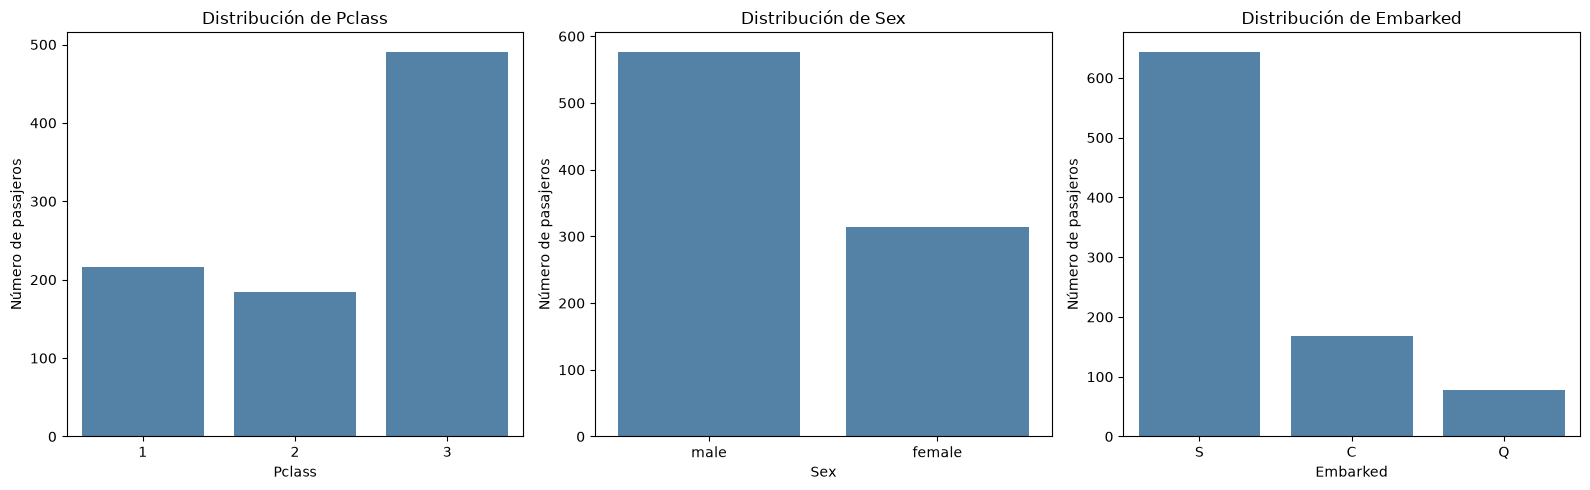

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Variables categóricas
categorical_features = ["Pclass", "Sex", "Embarked"]

# Crear una figura con 3 subgráficos
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Representar la distribución de cada variable
for i, feature in enumerate(categorical_features):
    sns.countplot(data=train, x=feature, ax=axes[i], color='steelblue')

    axes[i].set_title(f'Distribución de {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Número de pasajeros')

plt.tight_layout()
plt.show()

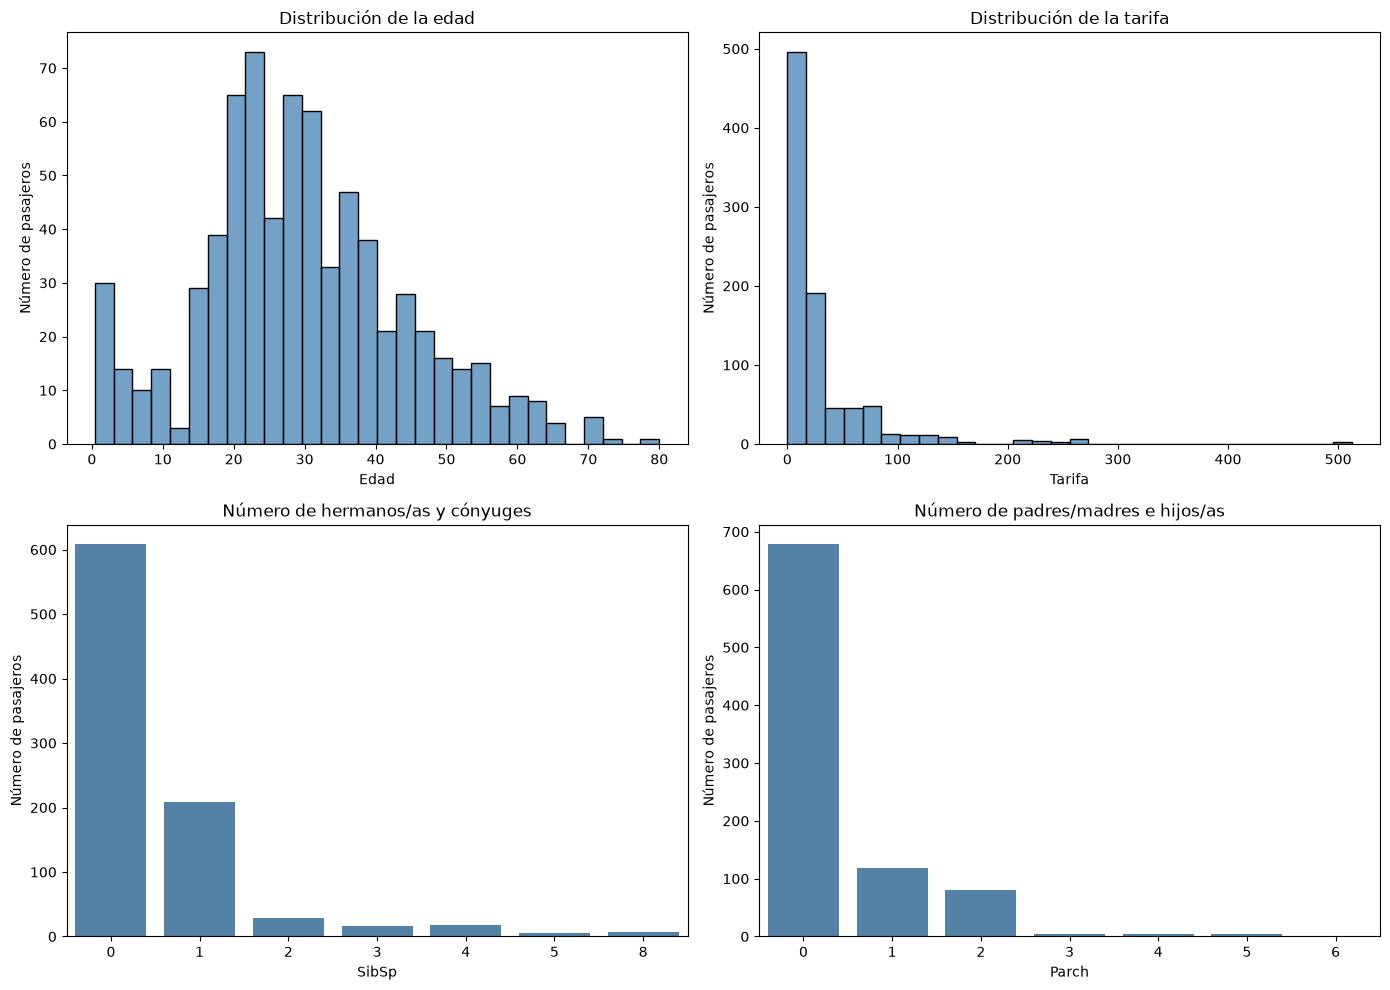

In [18]:
# Crear figura con 4 subgráficos
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histograma de la edad
sns.histplot(data=train, x='Age', bins=30, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Distribución de la edad')
axes[0, 0].set_xlabel('Edad')
axes[0, 0].set_ylabel('Número de pasajeros')

# Histograma de la tarifa
sns.histplot(data=train, x='Fare', bins=30, ax=axes[0, 1], color='steelblue')
axes[0, 1].set_title('Distribución de la tarifa')
axes[0, 1].set_xlabel('Tarifa')
axes[0, 1].set_ylabel('Número de pasajeros')

# Gráfico de barras de SibSp
sns.countplot(data=train, x='SibSp', ax=axes[1, 0], color='steelblue')
axes[1, 0].set_title('Número de hermanos/as y cónyuges')
axes[1, 0].set_xlabel('SibSp')
axes[1, 0].set_ylabel('Número de pasajeros')

# Gráfico de barras de Parch
sns.countplot(data=train, x='Parch', ax=axes[1, 1], color='steelblue')
axes[1, 1].set_title('Número de padres/madres e hijos/as')
axes[1, 1].set_xlabel('Parch')
axes[1, 1].set_ylabel('Número de pasajeros')

plt.tight_layout()
plt.show()

#### Diagramas de caja (*Boxplots*)

Los diagramas de caja o *boxplots* permiten visualizar cómo se distribuyen los valores de una variable numérica.

En ellos podemos identificar varios elementos:

- **Mediana:** valor central de los datos.
- **Cuartiles:** dividen los datos en cuatro partes iguales. La caja representa el 50 % central de las observaciones.
- **Bigotes:** muestran la extensión de los datos dentro de un rango determinado.
- **Valores atípicos (*outliers*):** observaciones que se alejan considerablemente del resto de los datos y aparecen representadas como puntos individuales.

Utilizaremos estos gráficos para analizar la distribución de la edad, la tarifa y el número de familiares a bordo, prestando especial atención a la posible presencia de valores atípicos.

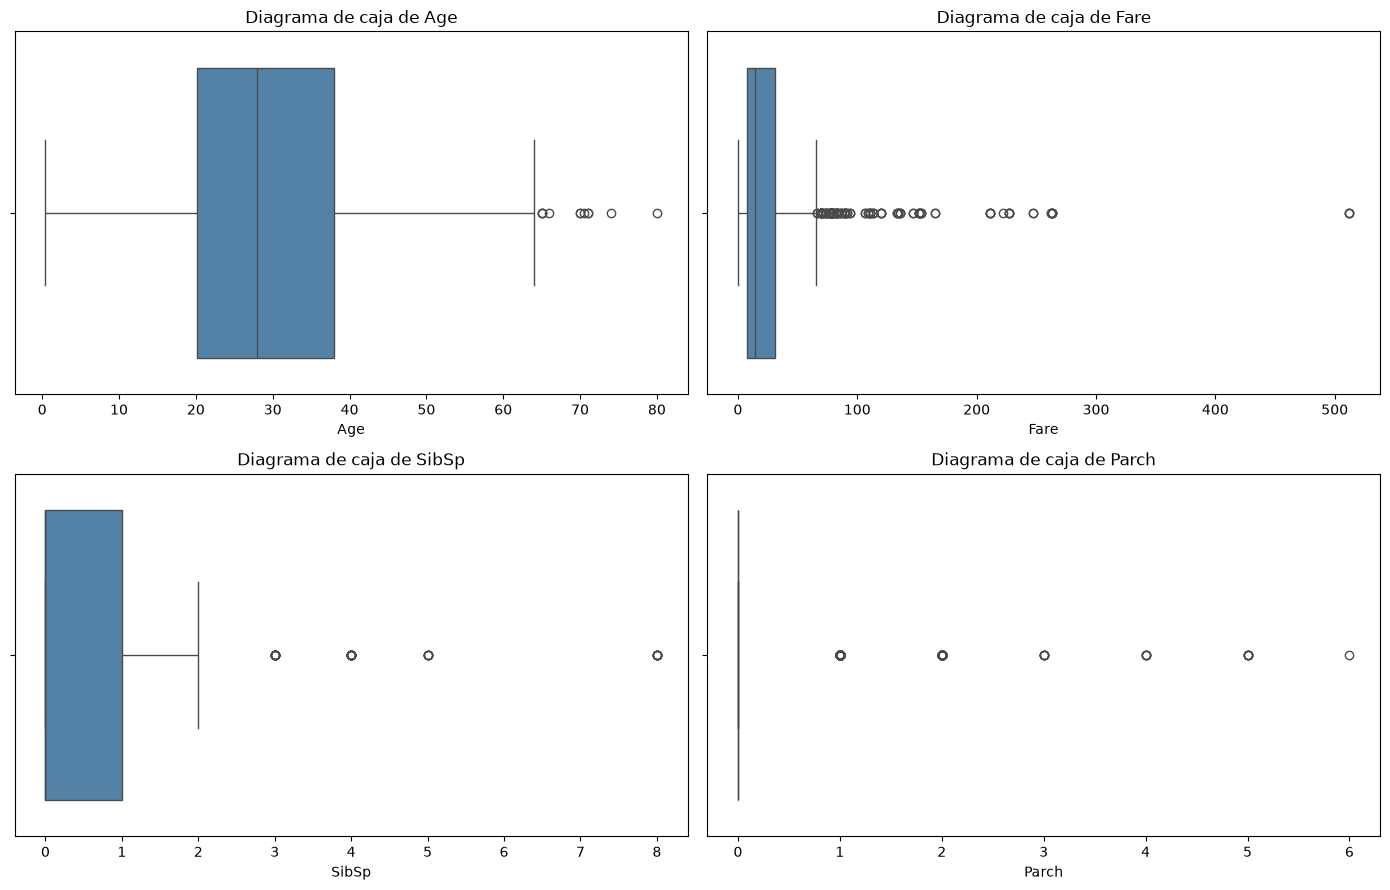

In [19]:

# Variables numéricas que vamos a analizar
numerical_features = ['Age', 'Fare', 'SibSp', 'Parch']

# Crear figura con 4 subgráficos
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Representar los boxplots
for i, feature in enumerate(numerical_features):
    sns.boxplot(data=train, x=feature, ax=axes[i // 2, i % 2], color='steelblue')
    
    axes[i // 2, i % 2].set_title(f'Diagrama de caja de {feature}')
    axes[i // 2, i % 2].set_xlabel(feature)

plt.tight_layout()
plt.show()


#### Distribución de la variable objetivo (*Target*)

Por último, analizaremos la distribución de la variable objetivo, `Survived`, que indica si un pasajero sobrevivió o no al hundimiento del Titanic.

Esta variable tiene dos posibles valores:

- `0`: el pasajero no sobrevivió.
- `1`: el pasajero sobrevivió.

Utilizaremos un gráfico de barras para visualizar el número de observaciones de cada clase y comprobar si existe un desequilibrio entre ambas.

Este análisis es importante porque nos permitirá conocer cómo se distribuyen las clases que nuestro futuro modelo tendrá que predecir.

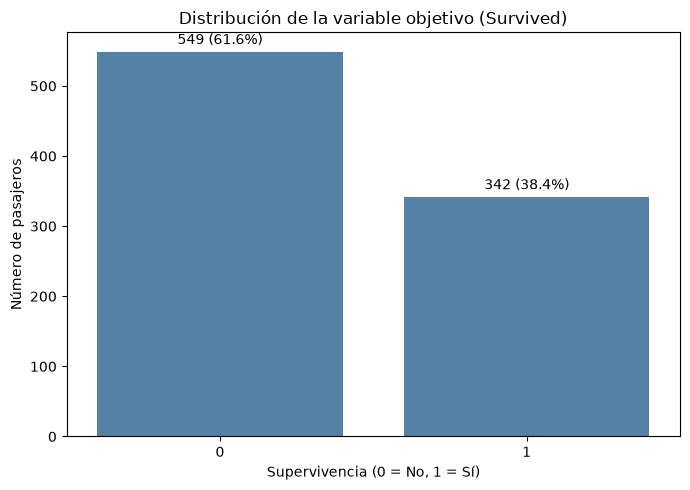

In [20]:

# Representar la distribución de la variable objetivo
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=train, x='Survived', color='steelblue')

# Añadir etiquetas con el número y porcentaje de pasajeros
total = len(train)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f'{int(value)} ({value / total:.1%})'
            for value in container.datavalues
        ],
        padding=3
    )

plt.title('Distribución de la variable objetivo (Survived)')
plt.xlabel('Supervivencia (0 = No, 1 = Sí)')
plt.ylabel('Número de pasajeros')
plt.tight_layout()
plt.show()


### Análisis de relaciones entre variables

Una vez conocidas las distribuciones individuales de las variables, vamos a profundizar en el análisis explorando las posibles relaciones que existen entre ellas.

En esta fase no nos limitaremos a representar los datos, sino que intentaremos plantear preguntas e hipótesis a partir de la información disponible y comprobar si los datos respaldan nuestras intuiciones.

Por ejemplo:

- ¿Pagaban más los pasajeros que viajaban en primera clase?
- ¿La edad de los pasajeros estaba relacionada con la clase en la que viajaban?
- ¿Los pasajeros que viajaban acompañados de familiares tenían características diferentes a los que viajaban solos?
- ¿Existían diferencias en la distribución de las tarifas según el puerto de embarque?

Este tipo de análisis nos ayudará a:

- **Identificar patrones:** descubrir comportamientos o tendencias que no son evidentes al observar cada variable por separado.
- **Detectar relaciones:** comprender cómo pueden estar relacionadas distintas características de los pasajeros.
- **Generar hipótesis:** plantear posibles explicaciones que podremos investigar posteriormente.
- **Conocer mejor los datos:** identificar qué variables podrían aportar información relevante para predecir la supervivencia.

No se trata de encontrar relaciones a toda costa, sino de aprender a formular preguntas interesantes y utilizar los datos para intentar responderlas.

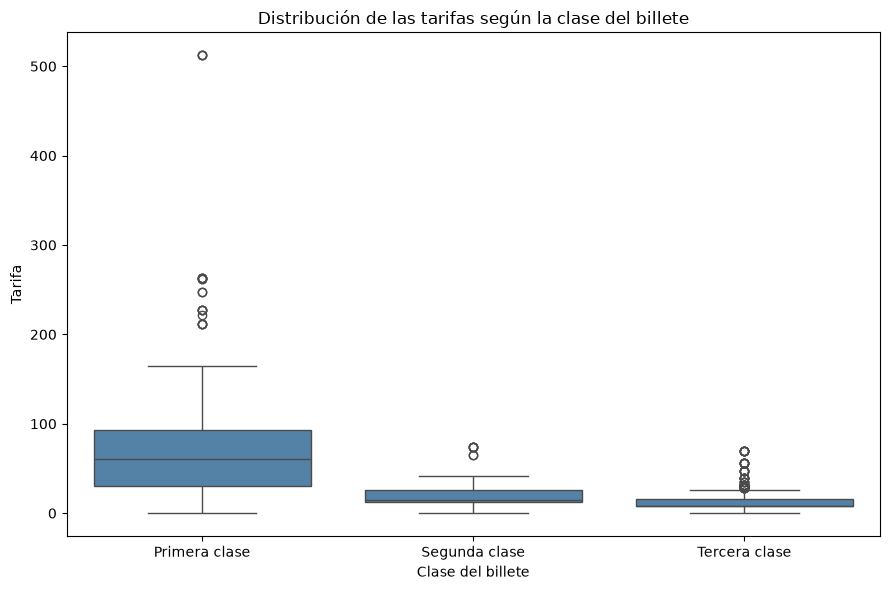

In [21]:
# Comparar la distribución de las tarifas según la clase del billete
plt.figure(figsize=(9, 6))

sns.boxplot(data=train, x='Pclass', y='Fare', color='steelblue')

plt.title('Distribución de las tarifas según la clase del billete')
plt.xlabel('Clase del billete')
plt.ylabel('Tarifa')
plt.xticks([0, 1, 2], ['Primera clase', 'Segunda clase', 'Tercera clase'])

plt.tight_layout()
plt.show()

Como cabía esperar, los pasajeros de primera clase pagaron tarifas considerablemente más elevadas que los de segunda y tercera clase.

La diferencia entre primera y segunda clase es especialmente notable. En cambio, las distribuciones de segunda y tercera clase están más próximas entre sí, aunque también existen diferencias entre ambas.

También podemos observar una mayor dispersión de las tarifas en primera clase, así como algunos valores especialmente elevados.

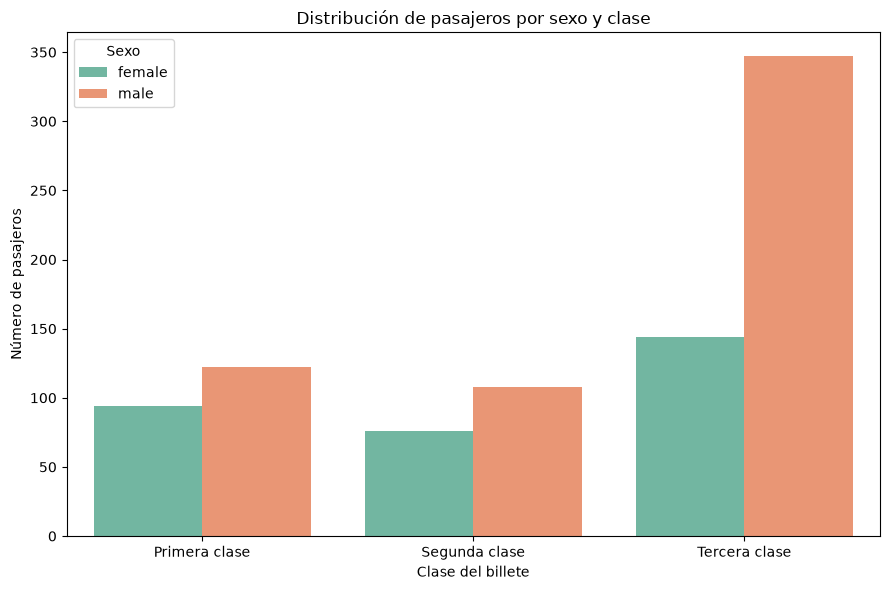

In [22]:
# Comparar el número de hombres y mujeres según la clase
plt.figure(figsize=(9, 6))

sns.countplot(data=train, x='Pclass', hue='Sex', palette='Set2')

plt.title('Distribución de pasajeros por sexo y clase')
plt.xlabel('Clase del billete')
plt.ylabel('Número de pasajeros')
plt.xticks([0, 1, 2], ['Primera clase', 'Segunda clase', 'Tercera clase'])
plt.legend(title='Sexo')

plt.tight_layout()
plt.show()


Observamos que los hombres se concentran principalmente en tercera clase, mientras que las mujeres presentan una distribución mucho más equilibrada entre las tres clases.

Esto sugiere que la distribución de las clases del billete era diferente según el sexo del pasajero.

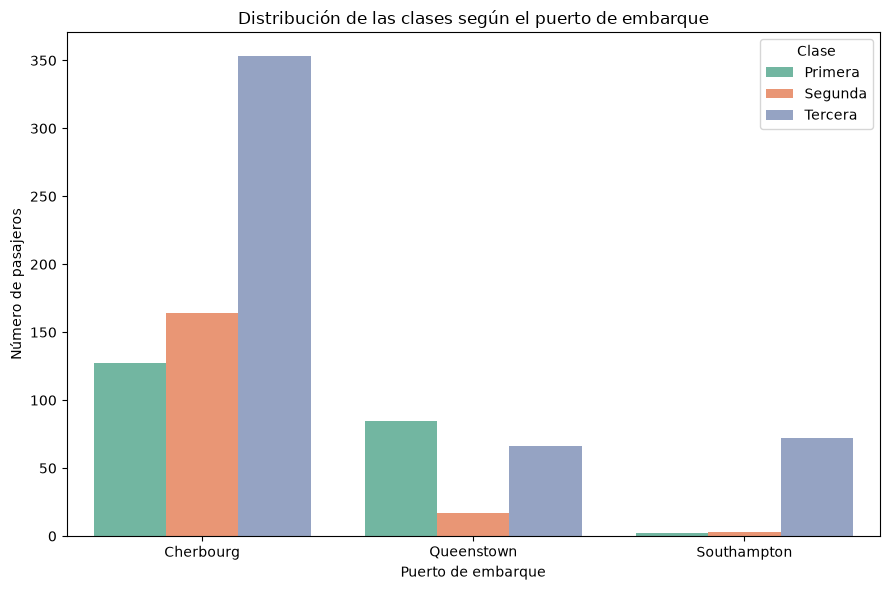

In [23]:
# Comparar el número de pasajeros por clase y puerto de embarque
plt.figure(figsize=(9, 6))

sns.countplot(data=train, x='Embarked', hue='Pclass', palette='Set2')

plt.title('Distribución de las clases según el puerto de embarque')
plt.xlabel('Puerto de embarque')
plt.ylabel('Número de pasajeros')
plt.xticks([0, 1, 2], ['Cherbourg', 'Queenstown', 'Southampton'])
plt.legend(title='Clase', labels=['Primera', 'Segunda', 'Tercera'])

plt.tight_layout()
plt.show()

Un resultado llamativo es el de Queenstown, donde el número de pasajeros de primera clase supera al de tercera, a diferencia de lo que ocurre en los otros dos puertos.

### Análisis de las variables respecto a la supervivencia

Hasta ahora hemos estudiado las variables de forma individual y hemos explorado algunas relaciones entre ellas. Sin embargo, nuestro objetivo final es construir un modelo capaz de predecir si un pasajero sobrevivió o no al hundimiento del Titanic.

Por ello, resulta especialmente importante analizar cómo se relaciona cada una de las características disponibles con nuestra variable objetivo, `Survived`.

A lo largo de este apartado investigaremos preguntas como:

- ¿Influyó el sexo del pasajero en sus posibilidades de supervivencia?
- ¿Tenían más probabilidades de sobrevivir los pasajeros de primera clase?
- ¿Existían diferencias según la edad?
- ¿Influyó el puerto de embarque?
- ¿Tenían más posibilidades de sobrevivir los pasajeros que viajaban acompañados?

Para ello utilizaremos diferentes visualizaciones y comparaciones estadísticas, intentando identificar patrones que puedan resultar útiles para nuestro futuro modelo.

**Es importante recordar que encontrar una asociación entre dos variables no implica necesariamente que exista una relación de causalidad.**

#### Sexo y Supervivencia

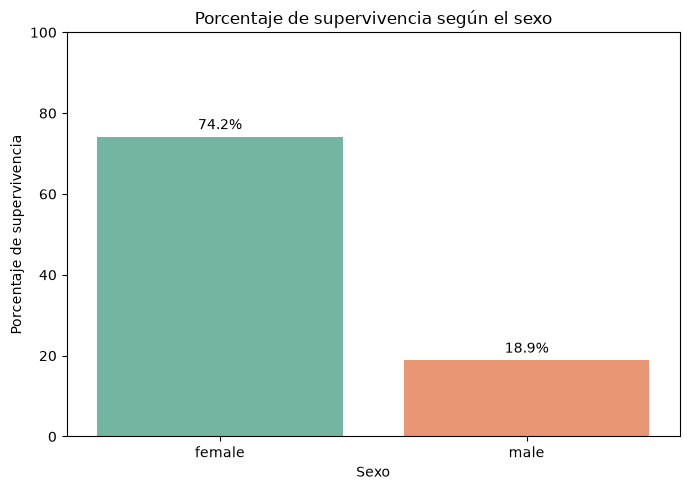

In [33]:

# Calcular el porcentaje de supervivencia según el sexo
survival_sex = train.groupby('Sex')['Survived'].mean() * 100

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=survival_sex.index,
    y=survival_sex.values,
    hue=survival_sex.index,
    palette='Set2',
    legend=False
)

# Mostrar porcentajes sobre las barras
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=3
    )

plt.title('Porcentaje de supervivencia según el sexo')
plt.xlabel('Sexo')
plt.ylabel('Porcentaje de supervivencia')
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

#### Clase y Supervivencia

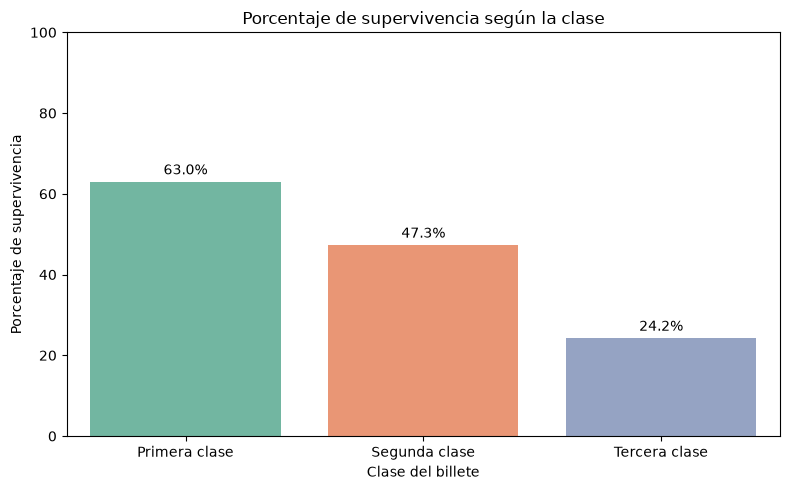

In [34]:
# Calcular el porcentaje de supervivencia según la clase
survival_class = train.groupby('Pclass')['Survived'].mean() * 100

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=survival_class.index,
    y=survival_class.values,
    hue=survival_class.index,
    palette='Set2',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Porcentaje de supervivencia según la clase')
plt.xlabel('Clase del billete')
plt.ylabel('Porcentaje de supervivencia')
plt.xticks([0, 1, 2], ['Primera clase', 'Segunda clase', 'Tercera clase'])
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

#### Edad y Supervivencia

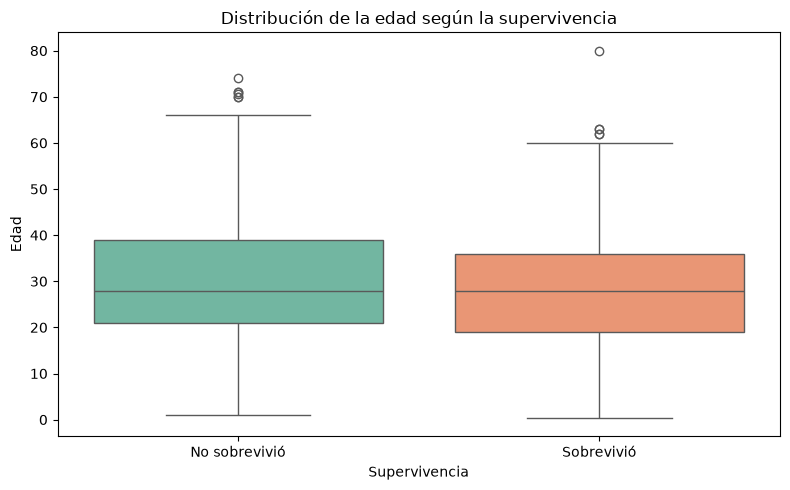

In [35]:
# Comparar la distribución de las edades según la supervivencia
age_survival = train[['Survived', 'Age']].dropna()

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=age_survival,
    x='Survived',
    y='Age',
    hue='Survived',
    palette='Set2',
    legend=False
)

plt.title('Distribución de la edad según la supervivencia')
plt.xlabel('Supervivencia')
plt.ylabel('Edad')
plt.xticks([0, 1], ['No sobrevivió', 'Sobrevivió'])
plt.tight_layout()
plt.show()

#### Tarifa y Supervivencia

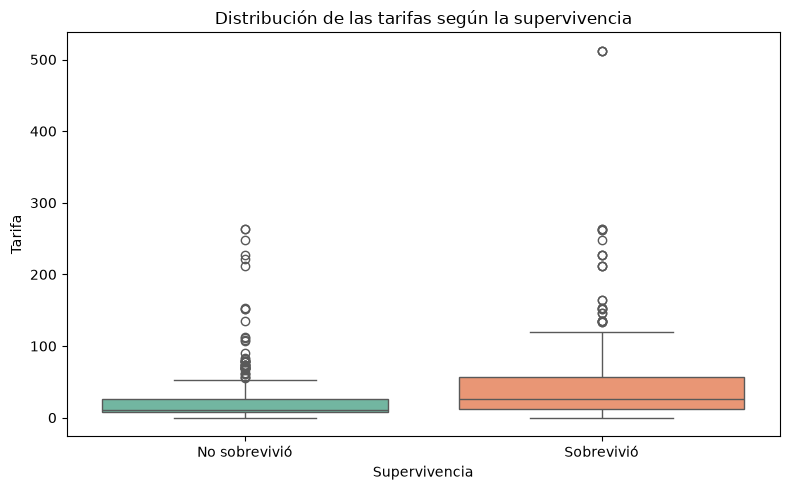

In [36]:
# Comparar la distribución de las tarifas según la supervivencia
fare_survival = train[['Survived', 'Fare']].dropna()

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=fare_survival,
    x='Survived',
    y='Fare',
    hue='Survived',
    palette='Set2',
    legend=False
)

plt.title('Distribución de las tarifas según la supervivencia')
plt.xlabel('Supervivencia')
plt.ylabel('Tarifa')
plt.xticks([0, 1], ['No sobrevivió', 'Sobrevivió'])
plt.tight_layout()
plt.show()

#### Hermanos/cónyuges a bordo y Supervivencia

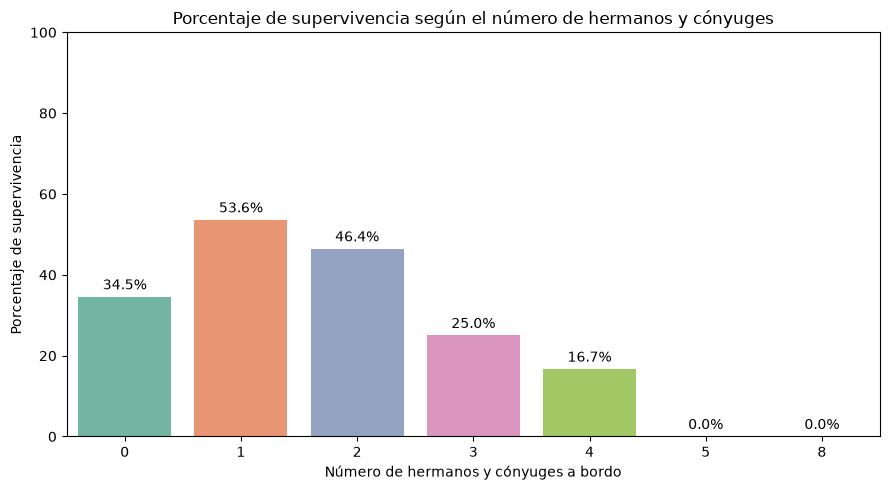

In [37]:
# Calcular el porcentaje de supervivencia según SibSp
survival_sibsp = train.groupby('SibSp')['Survived'].mean() * 100

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=survival_sibsp.index,
    y=survival_sibsp.values,
    hue=survival_sibsp.index,
    palette='Set2',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Porcentaje de supervivencia según el número de hermanos y cónyuges')
plt.xlabel('Número de hermanos y cónyuges a bordo')
plt.ylabel('Porcentaje de supervivencia')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

#### Padres/hijos a bordo y Supervivencia

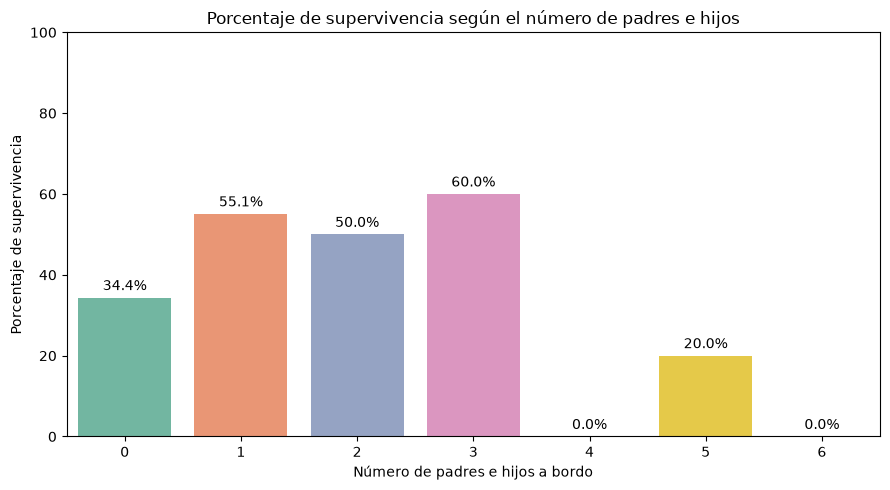

In [38]:
# Calcular el porcentaje de supervivencia según Parch
survival_parch = train.groupby('Parch')['Survived'].mean() * 100

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=survival_parch.index,
    y=survival_parch.values,
    hue=survival_parch.index,
    palette='Set2',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Porcentaje de supervivencia según el número de padres e hijos')
plt.xlabel('Número de padres e hijos a bordo')
plt.ylabel('Porcentaje de supervivencia')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

#### Punto de embarque y Supervivencia

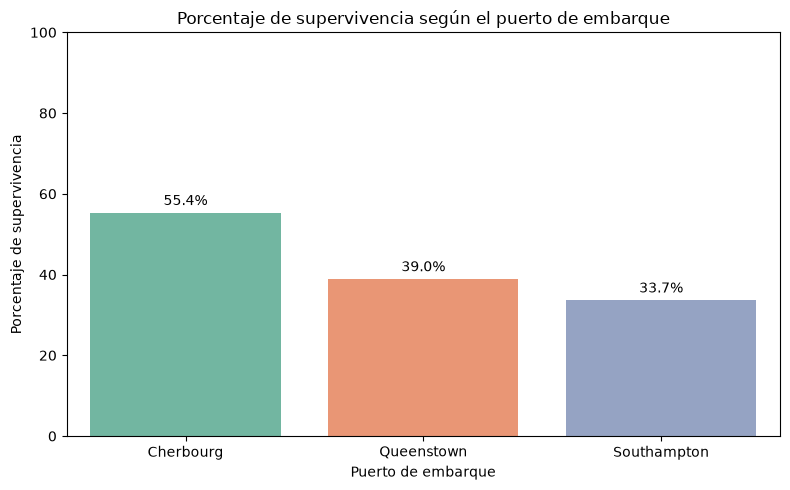

In [41]:
# Calcular el porcentaje de supervivencia según el puerto de embarque
survival_embarked = train.groupby('Embarked')['Survived'].mean() * 100

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=survival_embarked.index,
    y=survival_embarked.values,
    hue=survival_embarked.index,
    palette='Set2',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Porcentaje de supervivencia según el puerto de embarque')
plt.xlabel('Puerto de embarque')
plt.ylabel('Porcentaje de supervivencia')
plt.xticks(
    range(len(survival_embarked.index)),
    ['Cherbourg' if x == 'C' else 'Queenstown' if x == 'Q' else 'Southampton'
     for x in survival_embarked.index]
)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


### Análisis de correlaciones

Una vez estudiadas las distribuciones de las variables y su relación con la supervivencia, podemos profundizar en cómo se relacionan entre sí las distintas características de los pasajeros.

Para ello utilizaremos el **análisis de correlaciones**, una herramienta estadística que permite medir el grado de asociación entre dos variables.

La correlación nos ayuda a identificar patrones, por ejemplo:

- Si los pasajeros que pagaron tarifas más elevadas viajaban en clases superiores.
- Si existe alguna relación entre la edad y el número de familiares a bordo.
- Si determinadas características presentan alguna asociación con la supervivencia.

Es importante recordar que **correlación no implica causalidad**. Que dos variables estén relacionadas estadísticamente no significa que una sea necesariamente la causa de la otra.


#### El coeficiente de correlación de Pearson

Uno de los métodos más utilizados para medir la correlación entre dos variables numéricas es el **coeficiente de correlación de Pearson**.

Este coeficiente mide la intensidad y la dirección de la relación lineal entre dos variables. Su valor siempre se encuentra entre -1 y 1:

- **+1:** correlación positiva perfecta. Cuando una variable aumenta, la otra también lo hace siguiendo una relación lineal.
- **0:** ausencia de correlación lineal.
- **-1:** correlación negativa perfecta. Cuando una variable aumenta, la otra disminuye siguiendo una relación lineal.

Cuanto más se aproxima el coeficiente a -1 o a 1, más intensa es la relación lineal.

Matemáticamente, el coeficiente de Pearson se calcula dividiendo la covarianza entre ambas variables por el producto de sus desviaciones típicas:

$$
r_{xy} = \frac{\operatorname{Cov}(X,Y)}
{\sigma_X \cdot \sigma_Y}
$$

Otra forma de expresar su cálculo es:

$$
r_{xy} =
\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}
\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}
$$

Donde:
- $x_i$ e $y_i$ son los valores individuales de cada variable.
- $\bar{x}$ e $\bar{y}$ son sus respectivas medias.
- $n$ es el número de observaciones.

Por tanto, Pearson mide hasta qué punto dos variables presentan un comportamiento lineal conjunto.


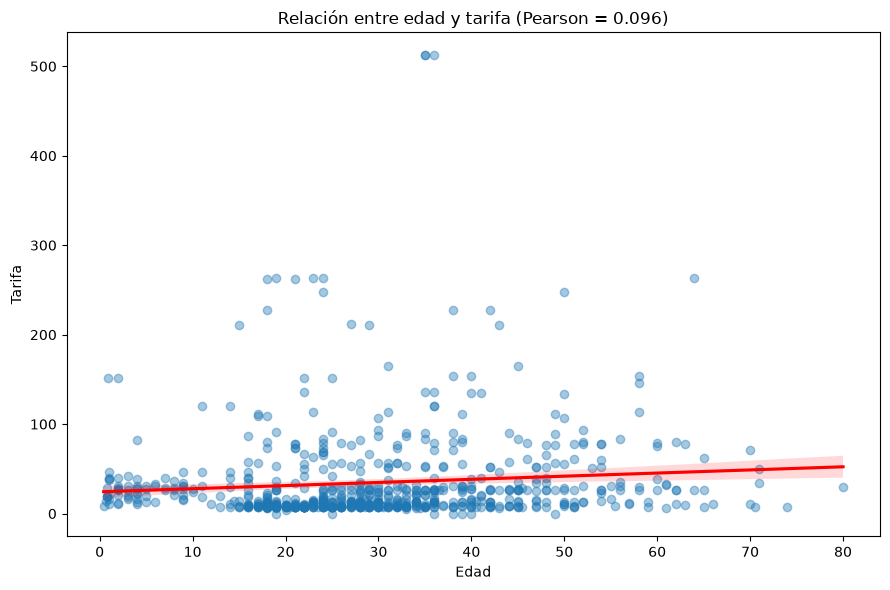

Correlación de Pearson: 0.0961


In [43]:
# Calcular la correlación de Pearson
correlation = train['Age'].corr(train['Fare'])

# Crear el diagrama de dispersión
plt.figure(figsize=(9, 6))

sns.regplot(
    data=train,
    x='Age',
    y='Fare',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.title(f'Relación entre edad y tarifa (Pearson = {correlation:.3f})')
plt.xlabel('Edad')
plt.ylabel('Tarifa')
plt.tight_layout()
plt.show()

print(f'Correlación de Pearson: {correlation:.4f}')



#### Preparación de las variables para el análisis

El coeficiente de Pearson necesita trabajar con variables numéricas. Sin embargo, en nuestro conjunto de datos también tenemos variables categóricas, como `Sex` y `Embarked`.

Para poder incluirlas en el análisis, necesitamos transformar sus categorías en valores numéricos. Una de las técnicas más utilizadas para ello es el **One-Hot Encoding**.

Esta técnica transforma una variable categórica en varias columnas binarias (0 o 1), una por cada categoría posible.

<img src="https://miro.medium.com/v2/resize:fit:1100/format:webp/1*1horDwZaIQ9BpMjL1gJryQ.png" alt="One-Hot Encoding - Google" width="650">

Por ejemplo, nuestra variable `Embarked` tiene tres categorías:

- C: Cherbourg.
- Q: Queenstown.
- S: Southampton.

Mediante One-Hot Encoding obtendríamos tres nuevas columnas:

| Embarked_C | Embarked_Q | Embarked_S |
|---|---|---|
| 1 | 0 | 0 |
| 0 | 1 | 0 |
| 0 | 0 | 1 |
| 0 | 0 | 1 |

Cada columna indica si el pasajero pertenece o no a una determinada categoría.

De esta forma, podemos representar las variables categóricas mediante valores numéricos sin asignarles artificialmente un orden.

En nuestro caso:

- `Sex`: podemos transformarla en una variable binaria.
- `Embarked`: utilizaremos One-Hot Encoding para obtener una columna por cada puerto de embarque.

Por otro lado, `Pclass` ya está representada mediante valores numéricos (1, 2 y 3), aunque debemos recordar que se trata de una variable ordinal y que Pearson interpreta esos valores como una escala numérica.

Finalmente, no incluiremos variables identificativas como `PassengerId`, `Name` o `Ticket`, ya que sus valores no representan cantidades numéricas útiles para este análisis.

In [44]:
# Crear una copia del dataset para el análisis de correlaciones
correlation_data = train.copy()

# Transformar Sex en una variable binaria
correlation_data['Sex'] = correlation_data['Sex'].map({
    'male': 0,
    'female': 1
})

# Aplicar One-Hot Encoding a Embarked
correlation_data = pd.get_dummies(
    correlation_data,
    columns=['Embarked'],
    prefix='Embarked',
    dtype=int
)

# Mostrar las primeras filas de las variables transformadas
correlation_data[
    ['Sex', 'Embarked_C', 'Embarked_Q', 'Embarked_S']
].head()


,Sex,Embarked_C,Embarked_Q,Embarked_S
0,0,0,0,1
1,1,1,0,0
2,1,0,0,1
3,1,0,0,1
4,0,0,0,1


#### Construcción de la matriz de correlaciones

Una vez transformadas las variables categóricas, ya podemos calcular una matriz de correlaciones que incluya todas las características seleccionadas.

Esta matriz recoge el coeficiente de Pearson para cada pareja de variables.

Cada celda representa una correlación entre dos variables. La diagonal principal siempre contiene valores iguales a 1, ya que cada variable presenta una correlación perfecta consigo misma.

Además, la matriz es simétrica: la correlación entre A y B es exactamente la misma que entre B y A.


In [45]:
# Seleccionar las variables que queremos incluir en el análisis
correlation_features = [
    'Survived',
    'Pclass',
    'Sex',
    'Age',
    'SibSp',
    'Parch',
    'Fare',
    'Embarked_C',
    'Embarked_Q',
    'Embarked_S'
]

# Calcular la matriz de correlaciones de Pearson
correlation_matrix = correlation_data[
    correlation_features
].corr(method='pearson')

# Mostrar la matriz
correlation_matrix

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
Survived,1.000000,-0.338481,0.543351,-0.077221,-0.035322,0.081629,0.257307,0.168240,0.003650,-0.155660
Pclass,-0.338481,1.000000,-0.131900,-0.369226,0.083081,0.018443,-0.549500,-0.243292,0.221009,0.081720
Sex,0.543351,-0.131900,1.000000,-0.093254,0.114631,0.245489,0.182333,0.082853,0.074115,-0.125722
Age,-0.077221,-0.369226,-0.093254,1.000000,-0.308247,-0.189119,0.096067,0.036261,-0.022405,-0.032523
SibSp,-0.035322,0.083081,0.114631,-0.308247,1.000000,0.414838,0.159651,-0.059528,-0.026354,0.070941
Parch,0.081629,0.018443,0.245489,-0.189119,0.414838,1.000000,0.216225,-0.011069,-0.081228,0.063036
Fare,0.257307,-0.549500,0.182333,0.096067,0.159651,0.216225,1.000000,0.269335,-0.117216,-0.166603
Embarked_C,0.168240,-0.243292,0.082853,0.036261,-0.059528,-0.011069,0.269335,1.000000,-0.148258,-0.778359
Embarked_Q,0.003650,0.221009,0.074115,-0.022405,-0.026354,-0.081228,-0.117216,-0.148258,1.000000,-0.496624
Embarked_S,-0.155660,0.081720,-0.125722,-0.032523,0.070941,0.063036,-0.166603,-0.778359,-0.496624,1.000000



#### Visualización de la matriz de correlaciones

Para facilitar la interpretación de los resultados, vamos a representar la matriz mediante un **mapa de calor (heatmap)**.

En esta visualización, cada celda representa una correlación y su color permite identificar rápidamente tanto su intensidad como su dirección:

- Los valores próximos a 1 indican correlaciones positivas.
- Los valores próximos a -1 indican correlaciones negativas.
- Los valores próximos a 0 indican una correlación lineal débil o inexistente.

Esta representación nos permitirá identificar de forma visual qué variables presentan mayores asociaciones entre sí y, especialmente, cuáles muestran una mayor correlación con nuestra variable objetivo, `Survived`.


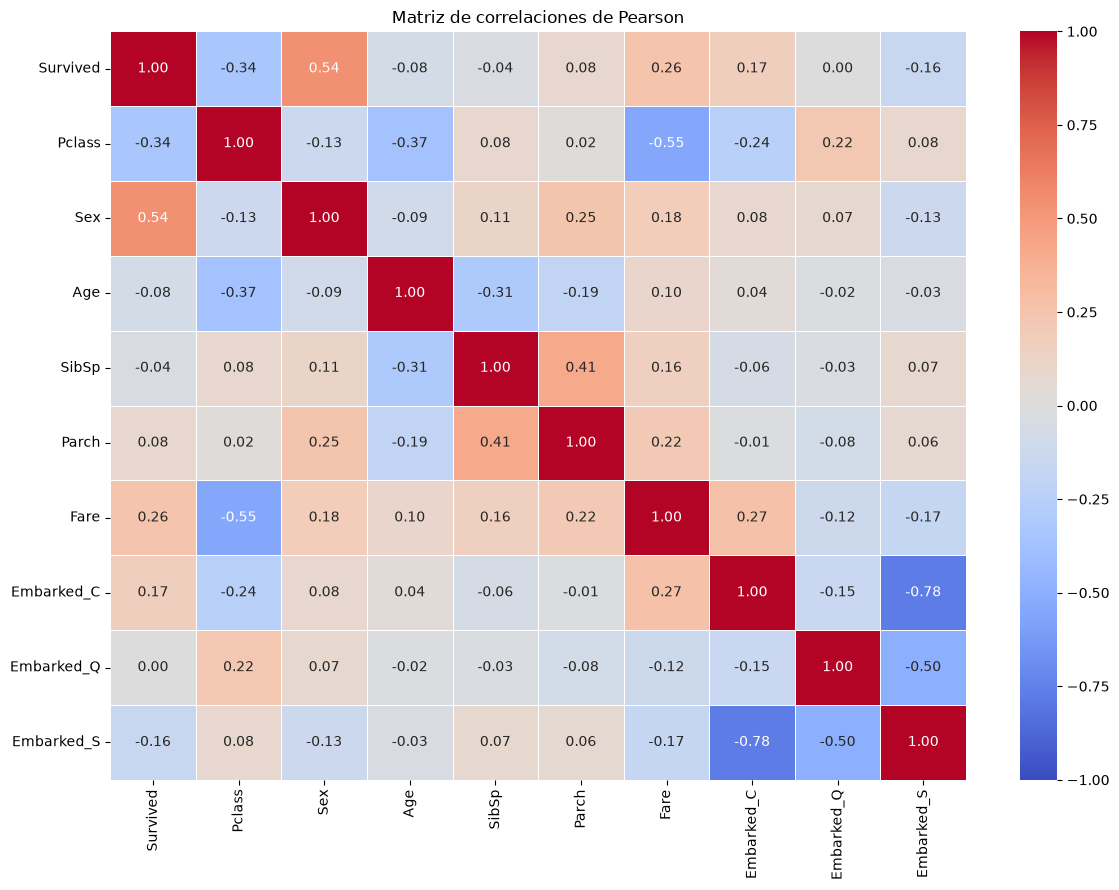

In [46]:
# Representar la matriz de correlaciones mediante un mapa de calor

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Matriz de correlaciones de Pearson')
plt.tight_layout()
plt.show()


**Interpretación de la matriz de correlaciones**: En primer lugar, nos centraremos en la primera fila de la matriz, correspondiente a nuestra variable objetivo, Survived. Nuestro interés es identificar qué características presentan una mayor correlación con la supervivencia, prestando especial atención a los valores positivos y negativos más elevados.

Observamos que las dos variables que presentan una mayor correlación con la supervivencia son Sex y Pclass.

Por un lado, encontramos una correlación positiva elevada con Sex. Recordemos que hemos codificado esta variable asignando el valor 1 a las mujeres y el 0 a los hombres. Por tanto, esta correlación positiva indica que ser mujer está asociado con una mayor probabilidad de supervivencia. Este resultado coincide con lo que habíamos observado anteriormente en nuestro análisis de la supervivencia según el sexo.

Por otro lado, encontramos una correlación negativa con Pclass. Esto significa que, a medida que aumenta el valor de la clase (pasando de primera a tercera), disminuye la probabilidad de supervivencia. Dicho de otra forma, los pasajeros de primera y segunda clase presentaban mayores probabilidades de sobrevivir que los de tercera clase. Nuevamente, este resultado confirma los patrones que habíamos identificado en los análisis anteriores.

Si nos fijamos ahora en el resto de la matriz, también podemos identificar algunas relaciones interesantes entre las variables predictoras.

Por ejemplo, observamos una correlación negativa entre Pclass y Fare. Esto tiene sentido: al aumentar el número de la clase (de primera a tercera), disminuye generalmente el precio pagado por el billete. Es decir, los pasajeros de primera clase tendían a pagar tarifas más elevadas que los de segunda y tercera clase.

También destaca la correlación positiva entre SibSp y Parch. Esto sugiere que los pasajeros que viajaban con hermanos/as o cónyuges también tendían a viajar con padres/madres o hijos/as. Una posible explicación es que muchas personas viajaban acompañadas de sus familias.

En definitiva, la matriz de correlaciones nos permite confirmar algunos de los patrones que ya habíamos identificado durante el análisis exploratorio y descubrir nuevas relaciones entre las características de los pasajeros.

Es importante recordar que estas correlaciones reflejan asociaciones estadísticas y no implican necesariamente relaciones de causalidad. Además, una correlación elevada no significa automáticamente que una variable sea más importante para cualquier modelo de Machine Learning.

## Feature Engineering

Hasta ahora hemos dedicado nuestro tiempo a explorar los datos originales, estudiar sus distribuciones e identificar posibles relaciones entre las características de los pasajeros y su supervivencia.

Sin embargo, los datos originales no siempre contienen las variables más adecuadas para construir un modelo predictivo. En ocasiones, podemos obtener información adicional combinando, transformando o extrayendo información de las variables que ya tenemos.

Este proceso se conoce como **Feature Engineering** (ingeniería de características).

Consiste en crear, transformar o seleccionar variables (*features*) a partir de los datos disponibles, con el objetivo de representar mejor la información y facilitar que los modelos de Machine Learning puedan identificar patrones relevantes.

En este apartado vamos a aplicar algunas técnicas sencillas sobre nuestro conjunto de datos:

- Combinar variables existentes para obtener nuevas características.
- Crear variables binarias que representen determinadas condiciones.
- Agrupar variables numéricas en categorías.
- Extraer información de variables de texto.

Después analizaremos las nuevas características y estudiaremos cómo se relacionan con nuestra variable objetivo, `Survived`.

>Nota: En datasets más complejos, esta parte de feature engineering puede requerir un conocimiento experto del tema en cuestión.

In [47]:
# Crear una copia para trabajar con Feature Engineering
train_fe = train.copy()

print(f'Dataset original: {train.shape}')
print(f'Dataset para Feature Engineering: {train_fe.shape}')

Dataset original: (891, 12)
Dataset para Feature Engineering: (891, 12)


### Tamaño de la familia (`FamilySize`)

En nuestro dataset tenemos dos variables relacionadas con los familiares que acompañaban a cada pasajero:

- `SibSp`: número de hermanos/as y cónyuges a bordo.
- `Parch`: número de padres/madres e hijos/as a bordo.

Podemos combinar ambas variables para obtener una nueva característica que represente el tamaño total de la familia que viajaba en el Titanic.

Para ello, sumamos ambas variables y añadimos 1, correspondiente al propio pasajero:

$$
\text{FamilySize} = \text{SibSp} + \text{Parch} + 1
$$

Esta nueva variable nos permite estudiar si el tamaño de la familia con la que viajaba una persona podía estar relacionado con sus posibilidades de supervivencia.

In [48]:
# Crear la variable FamilySize
train_fe['FamilySize'] = train_fe['SibSp'] + train_fe['Parch'] + 1

# Comprobar los resultados
train_fe[['SibSp', 'Parch', 'FamilySize']].head(10)

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1
5,0,0,1
6,0,0,1
7,3,1,5
8,0,2,3
9,1,0,2


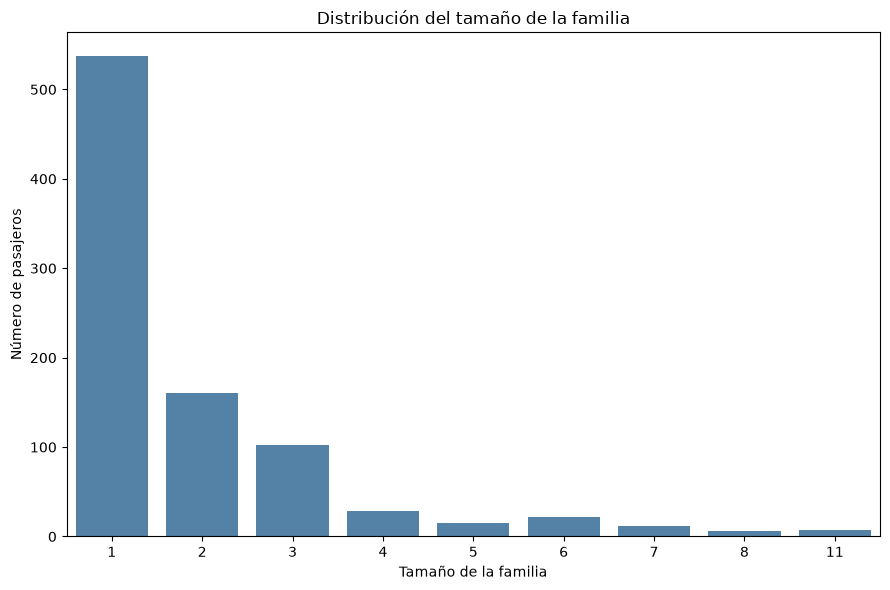

In [51]:
plt.figure(figsize=(9, 6))

ax = sns.countplot(data=train_fe, x='FamilySize', color='steelblue')

plt.title('Distribución del tamaño de la familia')
plt.xlabel('Tamaño de la familia')
plt.ylabel('Número de pasajeros')
plt.tight_layout()

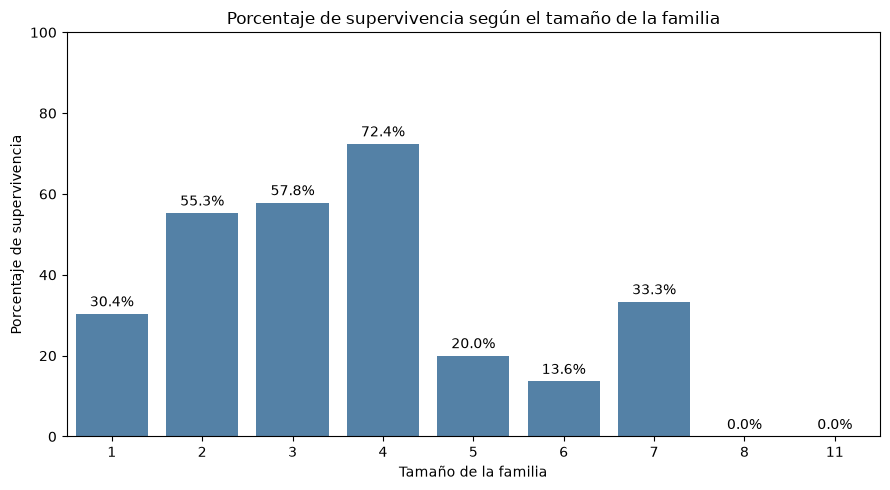

In [49]:
# Calcular el porcentaje de supervivencia para cada tamaño familiar
survival_family = train_fe.groupby('FamilySize')['Survived'].mean() * 100

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=survival_family.index,
    y=survival_family.values,
    color='steelblue'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Porcentaje de supervivencia según el tamaño de la familia')
plt.xlabel('Tamaño de la familia')
plt.ylabel('Porcentaje de supervivencia')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Viajar solo (`IsAlone`)

A partir de `FamilySize`, podemos crear otra variable que indique si un pasajero viajaba solo o acompañado.

La nueva característica tendrá dos posibles valores:

- `1`: el pasajero viajaba solo.
- `0`: el pasajero viajaba acompañado.

Esta transformación simplifica la información del tamaño familiar y nos permite estudiar específicamente si viajar solo estaba relacionado con las posibilidades de supervivencia.

In [52]:
# Crear la variable IsAlone
train_fe['IsAlone'] = (train_fe['FamilySize'] == 1).astype(int)

# Comprobar los resultados
train_fe[['FamilySize', 'IsAlone']].head(10)

,FamilySize,IsAlone
0,2,0
1,2,0
2,1,1
3,2,0
4,1,1
5,1,1
6,1,1
7,5,0
8,3,0
9,2,0


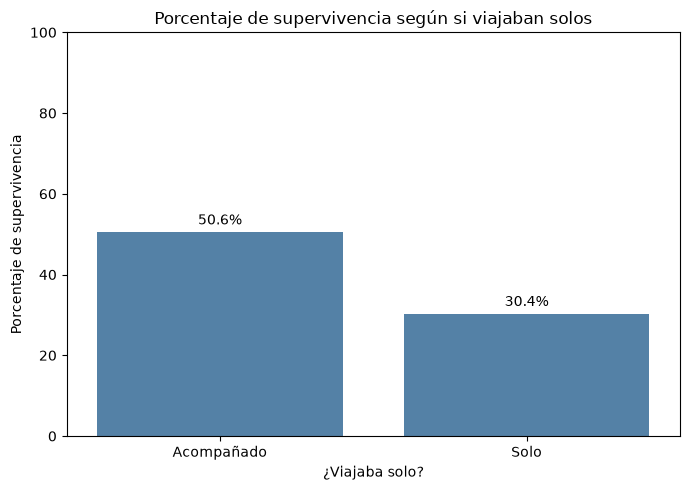

In [53]:
# Calcular el porcentaje de supervivencia según si viajaban solos
survival_alone = train_fe.groupby('IsAlone')['Survived'].mean() * 100

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=survival_alone.index,
    y=survival_alone.values,
    color='steelblue'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Porcentaje de supervivencia según si viajaban solos')
plt.xlabel('¿Viajaba solo?')
plt.ylabel('Porcentaje de supervivencia')
plt.xticks([0, 1], ['Acompañado', 'Solo'])
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


### Agrupación de edades (`AgeGroup`)

La edad es una variable numérica continua. Sin embargo, puede resultar interesante agrupar a los pasajeros en diferentes intervalos para estudiar si existían diferencias en las probabilidades de supervivencia según su etapa de vida.

Para ello crearemos una nueva variable categórica, `AgeGroup`, que clasificará a los pasajeros en cinco grupos:

- **Child:** menores de 12 años.
- **Teenager:** entre 12 y 17 años.
- **Young Adult:** entre 18 y 34 años.
- **Adult:** entre 35 y 59 años.
- **Senior:** 60 años o más.

Esta transformación nos permite estudiar la supervivencia desde una perspectiva diferente, comparando grupos de edad en lugar de valores individuales.

Es importante tener en cuenta que los límites de estos intervalos son decisiones que tomamos al preparar los datos. No existe una única división correcta y distintas agrupaciones podrían revelar patrones diferentes.

In [55]:
# Definir los intervalos y las etiquetas
age_bins = [0, 12, 18, 35, 60, float('inf')]
age_labels = ['Child', 'Teenager', 'Young Adult', 'Adult', 'Senior']

# Crear la nueva variable categórica
train_fe['AgeGroup'] = pd.cut(
    train_fe['Age'],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Comprobar los resultados
train_fe[['Age', 'AgeGroup']].head(10)


,Age,AgeGroup
0,22.0,Young Adult
1,38.0,Adult
2,26.0,Young Adult
3,35.0,Adult
4,35.0,Adult
5,NaN,NaN
6,54.0,Adult
7,2.0,Child
8,27.0,Young Adult
9,14.0,Teenager


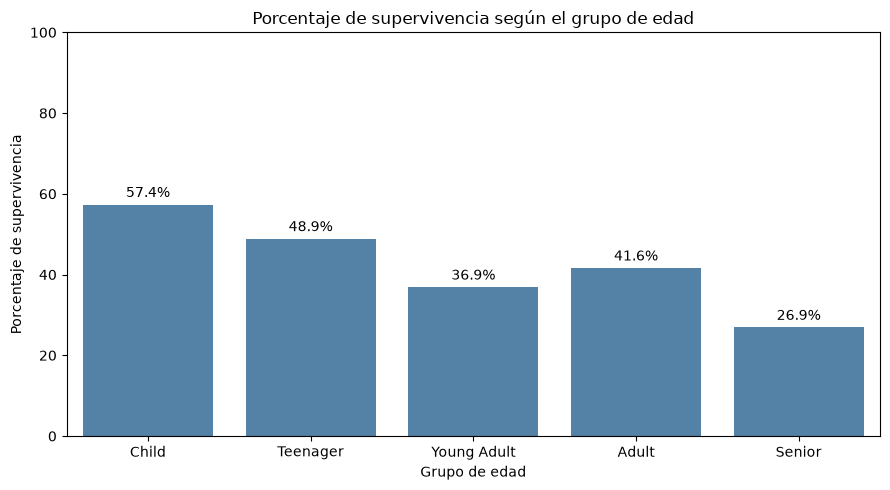

In [57]:
# Calcular el porcentaje de supervivencia por grupo de edad
survival_age = train_fe.groupby(
    'AgeGroup',
    observed=False
)['Survived'].mean() * 100

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=survival_age.index,
    y=survival_age.values,
    color='steelblue'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Porcentaje de supervivencia según el grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Porcentaje de supervivencia')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


### Extracción del título del nombre (`Title`)

La variable `Name` contiene el nombre completo de cada pasajero. Si observamos algunos registros, podemos comprobar que muchos nombres incluyen un tratamiento o título, como `Mr`, `Mrs`, `Miss` o `Master`.

Esta información puede resultar útil porque permite identificar características sociales y demográficas de los pasajeros.

Mediante técnicas de procesamiento de texto podemos extraer automáticamente estos títulos y almacenarlos en una nueva variable categórica, `Title`.

Por ejemplo:

- `Mr`: tratamiento utilizado habitualmente para hombres adultos.
- `Mrs`: tratamiento utilizado habitualmente para mujeres casadas.
- `Miss`: tratamiento utilizado habitualmente para mujeres jóvenes o solteras.
- `Master`: tratamiento utilizado habitualmente para niños.

Existen también otros títulos menos frecuentes. Para evitar tener demasiadas categorías con muy pocos pasajeros, agruparemos los títulos minoritarios bajo una categoría común denominada `Rare`.

De esta forma, convertimos una variable de texto relativamente compleja en una característica categórica más sencilla de analizar.


In [61]:
train["Name"].sample(20)

42                                   Kraeff, Mr. Theodor
249                        Carter, Rev. Ernest Courtenay
26                               Emir, Mr. Farred Chehab
195                                 Lurette, Miss. Elise
665                                   Hickman, Mr. Lewis
88                            Fortune, Miss. Mabel Helen
250                               Reed, Mr. James George
178                                   Hale, Mr. Reginald
679                   Cardeza, Mr. Thomas Drake Martinez
137                          Futrelle, Mr. Jacques Heath
225                         Berglund, Mr. Karl Ivar Sven
343           Sedgwick, Mr. Charles Frederick Waddington
334    Frauenthal, Mrs. Henry William (Clara Heinshei...
695                           Chapman, Mr. Charles Henry
64                                 Stewart, Mr. Albert A
382                                   Tikkanen, Mr. Juho
128                                    Peter, Miss. Anna
92                           Ch

In [62]:
# Extraer el título situado entre la coma y el punto del nombre
train_fe['Title'] = train_fe['Name'].str.extract(r',\s*([^\.]+)\.')

# Agrupar los títulos menos frecuentes
title_mapping = {
    'Mlle': 'Miss',
    'Ms': 'Miss',
    'Mme': 'Mrs'
}

train_fe['Title'] = train_fe['Title'].replace(title_mapping)

common_titles = ['Mr', 'Mrs', 'Miss', 'Master']

train_fe.loc[
    ~train_fe['Title'].isin(common_titles),
    'Title'
] = 'Rare'

# Comprobar los resultados
train_fe[['Name', 'Title']].head(15)


,Name,Title
0,"Braund, Mr. Owen Harris",Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs
2,"Heikkinen, Miss. Laina",Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs
4,"Allen, Mr. William Henry",Mr
5,"Moran, Mr. James",Mr
6,"McCarthy, Mr. Timothy J",Mr
7,"Palsson, Master. Gosta Leonard",Master
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs


In [64]:
# Mostrar algunos pasajeros cuyo título se ha agrupado como Rare
rare_passengers = train_fe.loc[
    train_fe['Title'] == 'Rare',
    ['Name', 'Title']
]

rare_passengers.head(15)

,Name,Title
30,"Uruchurtu, Don. Manuel E",Rare
149,"Byles, Rev. Thomas Roussel Davids",Rare
150,"Bateman, Rev. Robert James",Rare
245,"Minahan, Dr. William Edward",Rare
249,"Carter, Rev. Ernest Courtenay",Rare
317,"Moraweck, Dr. Ernest",Rare
398,"Pain, Dr. Alfred",Rare
449,"Peuchen, Major. Arthur Godfrey",Rare
536,"Butt, Major. Archibald Willingham",Rare
556,"Duff Gordon, Lady. (Lucille Christiana Sutherl...",Rare


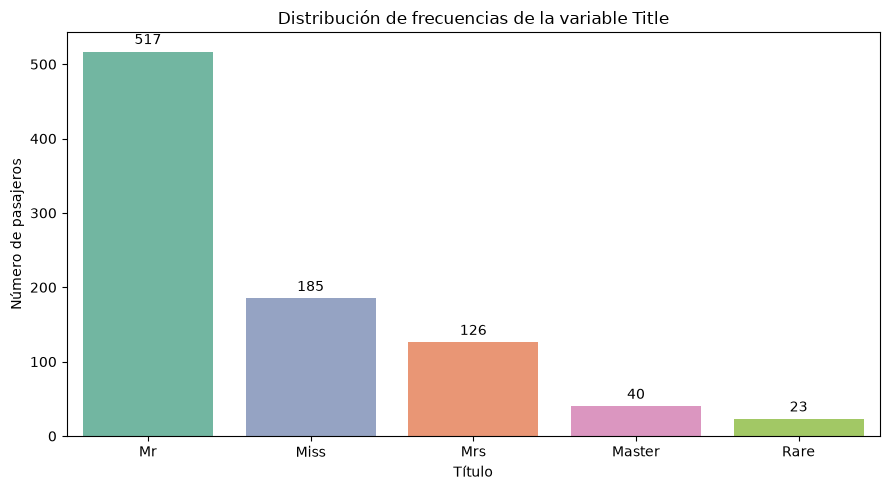

In [66]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=train_fe,
    x='Title',
    order=train_fe['Title'].value_counts().index,
    hue='Title',
    palette='Set2',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Distribución de frecuencias de la variable Title')
plt.xlabel('Título')
plt.ylabel('Número de pasajeros')
plt.tight_layout()
plt.show()

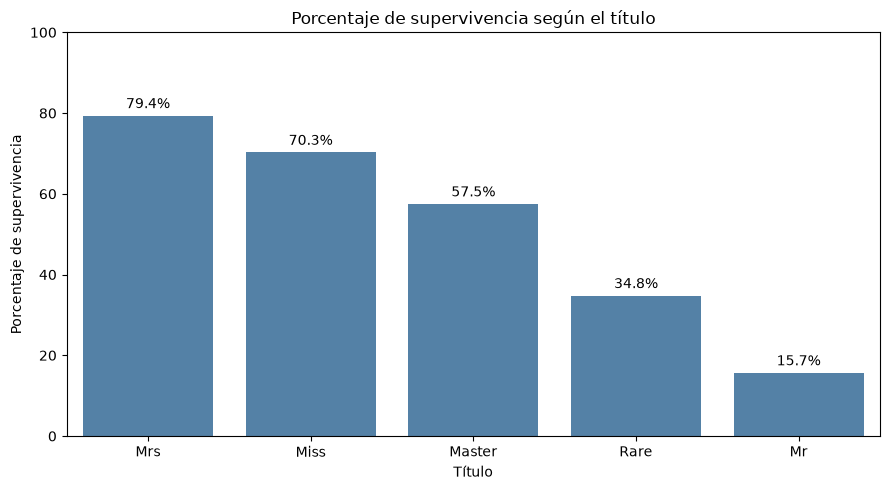

In [63]:
# Calcular el porcentaje de supervivencia por título
survival_title = train_fe.groupby('Title')['Survived'].mean() * 100

# Ordenar las categorías por porcentaje de supervivencia
survival_title = survival_title.sort_values(ascending=False)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=survival_title.index,
    y=survival_title.values,
    color='steelblue'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Porcentaje de supervivencia según el título')
plt.xlabel('Título')
plt.ylabel('Porcentaje de supervivencia')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


## Preparación de los datos (*Data Preprocessing*)

Una vez finalizado el análisis exploratorio y la creación de nuevas características (*Feature Engineering*), el siguiente paso consiste en preparar los datos para que puedan ser utilizados por los algoritmos de Machine Learning.

El objetivo de esta fase es transformar nuestro conjunto de datos en una estructura adecuada para el entrenamiento, asegurándonos de que las variables estén correctamente representadas y de que no existan problemas derivados de los valores ausentes o de los diferentes tipos de datos.

En esta fase realizaremos las siguientes operaciones:

1. **Selección de variables (*Feature Selection*):** decidir qué características utilizaremos para entrenar el modelo y cuáles descartaremos.
2. **Tratamiento de valores ausentes (*Missing Values*):** gestionar los valores que faltan en algunas variables.
3. **Codificación de variables categóricas (*Categorical Encoding*):** transformar las variables categóricas en representaciones numéricas que puedan interpretar los algoritmos.
4. **Escalado de variables (*Feature Scaling*):** ajustar las escalas de las variables numéricas cuando sea necesario.
5. **Separación de variables predictoras y objetivo:** construir los conjuntos `X` e `y`.
6. **División de los datos (*Train-Validation Split*):** separar los datos disponibles en un conjunto de entrenamiento y otro de validación para evaluar el rendimiento del modelo.

Es importante tener en cuenta que algunas transformaciones, como la imputación de valores ausentes o el escalado, deben aprenderse exclusivamente a partir del conjunto de entrenamiento. De esta manera evitamos introducir información del conjunto de validación durante el entrenamiento, un problema conocido como *data leakage* o fuga de información.

### Selección de variables (*Feature Selection*)

No todas las variables originales tienen por qué ser útiles para nuestro modelo. Algunas son identificadores, otras contienen información que ya hemos extraído mediante nuevas características y otras pueden requerir un tratamiento más específico.

Para construir nuestro primer modelo, partiremos de la siguiente selección:

| Variable | Decisión | Justificación |
|---|---|---|
| `Pclass` | Mantener | Clase del billete del pasajero. |
| `Sex` | Mantener | Variable con una relación importante con la supervivencia. |
| `Age` | Mantener | Edad exacta del pasajero. |
| `AgeGroup` | Mantener | Representa la edad mediante intervalos y puede ayudar a capturar patrones asociados a distintos grupos de edad. |
| `SibSp` | Mantener | Número de hermanos y cónyuges a bordo. |
| `Parch` | Mantener | Número de padres e hijos a bordo. |
| `Fare` | Mantener | Tarifa pagada por el pasajero. |
| `Embarked` | Mantener | Puerto de embarque. |
| `FamilySize` | Mantener | Tamaño total de la familia a bordo. |
| `IsAlone` | Mantener | Indica si el pasajero viajaba solo. |
| `Title` | Mantener | Tratamiento extraído del nombre. |
| `PassengerId` | Descartar | Identificador del pasajero. |
| `Name` | Descartar | Ya hemos extraído de esta variable la información del título. |
| `Ticket` | Descartar | Identificador del billete que requeriría un tratamiento específico. |
| `Cabin` | Descartar | Presenta un porcentaje muy elevado de valores ausentes. |

Algunas de las variables seleccionadas están relacionadas entre sí. Por ejemplo, `FamilySize` se obtiene a partir de `SibSp` y `Parch`, mientras que `AgeGroup` se construye a partir de `Age`. Sin embargo, esto no significa necesariamente que debamos eliminar alguna de ellas.

Podemos conservar estas representaciones inicialmente y comprobar durante la evaluación si aportan información útil al modelo.


In [67]:
# Variables seleccionadas para el primer modelo
selected_features = [
    'Pclass',
    'Sex',
    'Age',
    'AgeGroup',
    'SibSp',
    'Parch',
    'Fare',
    'Embarked',
    'FamilySize',
    'IsAlone',
    'Title'
]

# Construimos el conjunto de datos de trabajo
model_data = train_fe[selected_features + ['Survived']].copy()

model_data.head()

,Pclass,Sex,Age,AgeGroup,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title,Survived
0,3,male,22.0,Young Adult,1,0,7.2500,S,2,0,Mr,0
1,1,female,38.0,Adult,1,0,71.2833,C,2,0,Mrs,1
2,3,female,26.0,Young Adult,0,0,7.9250,S,1,1,Miss,1
3,1,female,35.0,Adult,1,0,53.1000,S,2,0,Mrs,1
4,3,male,35.0,Adult,0,0,8.0500,S,1,1,Mr,0


In [69]:
missing_values = pd.DataFrame({
    'Missing values': model_data.isnull().sum(),
    'Percentage': (model_data.isnull().mean() * 100).round(2)
})

missing_values.sort_values(
    by='Percentage',
    ascending=False
)

,Missing values,Percentage
AgeGroup,177,19.87
Age,177,19.87
Embarked,2,0.22
Sex,0,0.00
Pclass,0,0.00
SibSp,0,0.00
Parch,0,0.00
Fare,0,0.00
FamilySize,0,0.00
IsAlone,0,0.00


### Tratamiento de valores ausentes (*Missing Values*)

Como hemos observado durante el análisis exploratorio, algunas variables de nuestro conjunto de datos contienen valores ausentes (`NaN`). Por ejemplo, no conocemos la edad de todos los pasajeros ni disponemos de la tarifa de todos ellos.

Existen diferentes alternativas:

- **Eliminar observaciones:** descartar las filas que contienen valores ausentes. Puede ser razonable cuando su número es muy reducido, pero supone perder información.
- **Imputar con la media:** sustituir los valores ausentes de una variable numérica por su media. Es una alternativa sencilla, aunque puede verse afectada por valores extremos.
- **Imputar con la mediana:** utilizar la mediana de la variable. Suele ser más robusta cuando existen distribuciones asimétricas o valores atípicos.
- **Imputar con la moda:** sustituir los valores ausentes de una variable categórica por su categoría más frecuente.
- **Crear una categoría específica:** en determinadas variables categóricas, podemos representar la ausencia de información como una categoría adicional.


Sin embargo, no siempre es necesario realizar estas operaciones. Algunos algoritmos de Machine Learning incorporan mecanismos propios para gestionar los valores ausentes durante el entrenamiento y la predicción.

En nuestro caso, vamos a trabajar inicialmente con modelos cuyas implementaciones admiten valores ausentes de forma nativa. Por tanto, **no realizaremos imputación ni eliminaremos las observaciones que contengan valores ausentes**.

Esto nos permite conservar toda la información disponible y evitar introducir valores artificiales en nuestro conjunto de datos.

Es importante señalar que esta capacidad depende del algoritmo y de su implementación concreta. No todos los modelos admiten valores ausentes directamente, por lo que tendremos que tenerlo en cuenta si posteriormente incorporamos otros algoritmos a la comparación.


In [70]:
# Separar variables predictoras y objetivo
X = model_data.drop(columns='Survived').copy()
y = model_data['Survived'].copy()

# Codificar la variable Sex
X['Sex'] = X['Sex'].map({
    'male': 0,
    'female': 1
})

X.head()

,Pclass,Sex,Age,AgeGroup,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title
0,3,0,22.0,Young Adult,1,0,7.2500,S,2,0,Mr
1,1,1,38.0,Adult,1,0,71.2833,C,2,0,Mrs
2,3,1,26.0,Young Adult,0,0,7.9250,S,1,1,Miss
3,1,1,35.0,Adult,1,0,53.1000,S,2,0,Mrs
4,3,0,35.0,Adult,0,0,8.0500,S,1,1,Mr


###  División de los datos (*Train-Validation Split*)

Antes de entrenar nuestros modelos, debemos dividir los datos disponibles en dos subconjuntos:

- **Entrenamiento:** se utilizará para que el algoritmo aprenda las relaciones entre las características y la supervivencia.
- **Validación:** se utilizará para evaluar el rendimiento del modelo sobre observaciones que no ha utilizado durante el entrenamiento.

Utilizaremos una división del 80 % para entrenamiento y el 20 % para validación.

Además, aplicaremos una división estratificada (*stratified split*), de manera que ambos subconjuntos mantengan aproximadamente la misma proporción de pasajeros supervivientes y no supervivientes.

De esta forma podremos evaluar el modelo de una manera más representativa.


In [71]:
from sklearn.model_selection import train_test_split

# Dividir el conjunto de datos en entrenamiento y prueba
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Tamaño de X_train: {X_train.shape}')
print(f'Tamaño de X_val:   {X_val.shape}')

Tamaño de X_train: (712, 11)
Tamaño de X_val:   (179, 11)


In [72]:
# Comprobamos la distribución de la variable objetivo en los conjuntos de entrenamiento y validación
distribution = pd.DataFrame({
    'Train': y_train.value_counts(normalize=True) * 100,
    'Validation': y_val.value_counts(normalize=True) * 100
})

distribution.index = ['No sobrevivió', 'Sobrevivió']

distribution.round(2)

,Train,Validation
No sobrevivió,61.66,61.45
Sobrevivió,38.34,38.55


### Transformación de variables categóricas

Una vez separados los conjuntos de entrenamiento y validación, aplicaremos la codificación One-Hot Encoding a las variables categóricas.

Es importante realizar esta transformación después de la división de los datos. Así evitamos que la información del conjunto de validación intervenga en el aprendizaje de las transformaciones.

Utilizaremos `OneHotEncoder` de Scikit-learn, que permite transformar automáticamente las categorías en columnas binarias.

Además, configuraremos `handle_unknown='ignore'` para que el proceso pueda gestionar categorías que aparezcan durante la transformación y que no estuvieran presentes en el conjunto de entrenamiento.

En este caso no necesitamos aplicar imputación ni escalado: conservaremos los valores ausentes y trabajaremos inicialmente con modelos basados en árboles que no requieren estandarizar las variables numéricas.

In [76]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    'AgeGroup',
    'Embarked',
    'Title'
]

# El resto de las variables ya tienen representación numérica
numeric_features = [
    'Pclass',
    'Sex',
    'Age',
    'SibSp',
    'Parch',
    'Fare',
    'FamilySize',
    'IsAlone'
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ],
    remainder='passthrough'
)

# Aprender las categorías únicamente a partir del conjunto de entrenamiento (en este caso es indiferente, pero es una buena práctica)
X_train_processed = preprocessor.fit_transform(X_train)

# Aplicar la misma transformación al conjunto de validación
X_val_processed = preprocessor.transform(X_val)

print(f'Forma original de X_train: {X_train.shape}')
print(f'Forma procesada de X_train: {X_train_processed.shape}')

print(f'Forma original de X_val: {X_val.shape}')
print(f'Forma procesada de X_val: {X_val_processed.shape}')

Forma original de X_train: (712, 11)
Forma procesada de X_train: (712, 23)
Forma original de X_val: (179, 11)
Forma procesada de X_val: (179, 23)


In [75]:
# Obtener los nombres de las variables después de la transformación
feature_names = preprocessor.get_feature_names_out()

# Convertir los resultados a DataFrames para facilitar su visualización
X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_val_processed = pd.DataFrame(
    X_val_processed,
    columns=feature_names,
    index=X_val.index
)

X_train_processed.head()

,cat__AgeGroup_Adult,cat__AgeGroup_Child,cat__AgeGroup_Senior,cat__AgeGroup_Teenager,cat__AgeGroup_Young Adult,cat__AgeGroup_nan,cat__Embarked_C,cat__Embarked_Q,cat__Embarked_S,cat__Embarked_nan,...,cat__Title_Mrs,cat__Title_Rare,remainder__Pclass,remainder__Sex,remainder__Age,remainder__SibSp,remainder__Parch,remainder__Fare,remainder__FamilySize,remainder__IsAlone
692,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,3.0,0.0,NaN,0.0,0.0,56.4958,1.0,1.0
481,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,2.0,0.0,NaN,0.0,0.0,0.0000,1.0,1.0
527,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,NaN,0.0,0.0,221.7792,1.0,1.0
855,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,1.0,18.0,0.0,1.0,9.3500,2.0,0.0
801,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,2.0,1.0,31.0,1.0,1.0,26.2500,3.0,0.0


### Resultado del preprocesamiento

Hemos completado la preparación inicial de nuestros datos:

- Hemos seleccionado las características que utilizaremos en nuestro primer modelo.
- Hemos conservado los valores ausentes, sin realizar imputaciones ni eliminar observaciones.
- Hemos codificado las variables categóricas mediante One-Hot Encoding.
- Hemos separado las variables predictoras (`X`) de la variable objetivo (`y`).
- Hemos dividido los datos en conjuntos de entrenamiento y validación.

Disponemos ahora de dos conjuntos de datos con las mismas características, preparados para entrenar y evaluar nuestros modelos de clasificación.

En la siguiente fase comenzaremos con el entrenamiento de nuestro primer algoritmo de Machine Learning.

**Nota:** esta preparación está diseñada para los algoritmos que admiten valores ausentes de forma nativa. Si incorporamos modelos que no dispongan de esta funcionalidad, tendremos que adaptar el preprocesamiento.

## Primer modelo: árbol de decisión

Vamos a comenzar el entrenamiento de nuestros primeros modelos de Machine Learning. Para ello, empezaremos con un algoritmo sencillo e intuitivo: el **árbol de decisión (Decision Tree)**.

Un árbol de decisión es un algoritmo de aprendizaje supervisado que permite resolver problemas tanto de clasificación como de regresión. En nuestro caso, lo utilizaremos para resolver un problema de clasificación binaria: predecir si un pasajero sobrevivió o no al hundimiento del Titanic.

Su funcionamiento consiste en realizar una sucesión de preguntas sobre las características de los pasajeros. Cada respuesta conduce a una nueva pregunta o, finalmente, a una predicción.

### ¿Cómo funciona un árbol de decisión?

La estructura de un árbol de decisión está formada por los siguientes elementos:

- **Nodo raíz:** representa la primera pregunta que realiza el modelo.
- **Nodos internos:** contienen preguntas adicionales que permiten dividir los datos.
- **Ramas:** representan las posibles respuestas a cada pregunta.
- **Hojas:** representan el resultado final o predicción del modelo.

Por ejemplo, nuestro árbol podría comenzar preguntándose si el pasajero era hombre o mujer. Dependiendo de la respuesta, podría continuar preguntándose por la clase del billete, la edad o el tamaño de la familia, hasta llegar a una predicción de supervivencia.

El objetivo del algoritmo es encontrar las preguntas y divisiones que permitan separar mejor a los pasajeros que sobrevivieron de aquellos que no lo hicieron.


![Decision Tree - Google](https://cdn-icons-png.flaticon.com/512/5139/5139787.png)

### ¿Cómo aprende el modelo?

Durante el entrenamiento, el algoritmo analiza las variables disponibles y busca qué división permite separar mejor las observaciones según su clase.

Para ello, utiliza diferentes criterios que miden la pureza de los grupos resultantes. Dos de los más habituales son:

- **Índice Gini:** mide la probabilidad de clasificar incorrectamente una observación si se asignase una clase al azar siguiendo la distribución de clases del grupo.
- **Entropía:** mide el grado de desorden o incertidumbre existente en un conjunto de observaciones.

El algoritmo selecciona las divisiones que reducen más la impureza y repite el proceso en las distintas ramas del árbol.

Este procedimiento continúa hasta alcanzar determinados criterios de parada, como una profundidad máxima o un número mínimo de observaciones por hoja.

Es importante controlar el crecimiento del árbol. Si alcanza demasiada profundidad, puede aprender patrones demasiado específicos del conjunto de entrenamiento y funcionar peor con datos nuevos. Este fenómeno se conoce como **sobreajuste (overfitting)**.


### Entrenamiento del árbol de decisión

Antes de entrenar el modelo, debemos recordar que los algoritmos de Scikit-learn necesitan recibir las variables en un formato adecuado.

En nuestro caso, ya hemos separado los datos en entrenamiento y validación. También hemos identificado las variables categóricas y las hemos preparado mediante One-Hot Encoding.

Vamos a utilizar `DecisionTreeClassifier`, la implementación de árboles de decisión para problemas de clasificación de Scikit-learn.

Una de las ventajas de los árboles de decisión es que no necesitan que las variables numéricas estén escaladas o normalizadas. Además, las implementaciones recientes de Scikit-learn permiten trabajar directamente con valores ausentes.

In [77]:
from sklearn.tree import DecisionTreeClassifier

### Creación y entrenamiento del modelo

Para entrenar nuestro primer árbol vamos a utilizar los siguientes parámetros:

- `criterion`: criterio utilizado para evaluar la calidad de las divisiones. Empezaremos utilizando el índice Gini.
- `max_depth`: profundidad máxima que podrá alcanzar el árbol. Limitaremos su crecimiento para evitar un posible sobreajuste.
- `min_samples_leaf`: número mínimo de observaciones que debe contener cada hoja.
- `random_state`: permite reproducir los resultados.

No vamos a buscar todavía la configuración óptima. El objetivo es entrenar un primer modelo sencillo y utilizarlo como referencia para las comparaciones posteriores.

El entrenamiento se realiza mediante el método `fit()`, al que proporcionamos las variables predictoras (`X_train_processed`) y las etiquetas reales (`y_train`).


<div align="center">
  <img src="https://images.openai.com/static-rsc-4/PGnuMKDzRLlSn3-DBBdS2p-ksEkrlu_3H3YI-QFD69itUpGVBrQ3DVWa8Ckl4nB4olDdW5Vk5HnATIiQk2oZS3tOGk06Wg8KEFlHzZMsgOlleXFH7TolfLtCgSK08s74cINqbtwF3OKVIxPc7uHwloP-U7fi2S5CYqtQHM4OoBT5Yxo7Lu15xFcjmWEddjFo?purpose=fullsize" width="45%">
  <img src="https://images.openai.com/static-rsc-4/AQnlylnVrVhYniDeBBjvf33k7vfCYPwLlUvViPKu1HhgSuSHOVTgOrEdl9JFdC_FmgH10pB5DRdV8IJJ9LC6WFyK-l6LU_fvdRSdhmQ6u_B5FfvfTljFyZVosSAH4Pvu0Se6hHUsLhIUvTLjUJ1-yWJuYHwAuHCqK8syzMvHfRG4bR0W3aEui0wMt3TynOTh?purpose=fullsize" width="45%">
</div>

<div align="center">
  <em> Efecto de los parámetros max_depth y min_samples_leaf sobre la estructura del árbol.</em>
</div>

In [79]:
# Creación del modelo de árbol de decisión con hiperparámetros ajustados
decision_tree = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    min_samples_leaf=10,
    random_state=42
)

# Entrenamiento del modelo
decision_tree.fit(X_train_processed, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

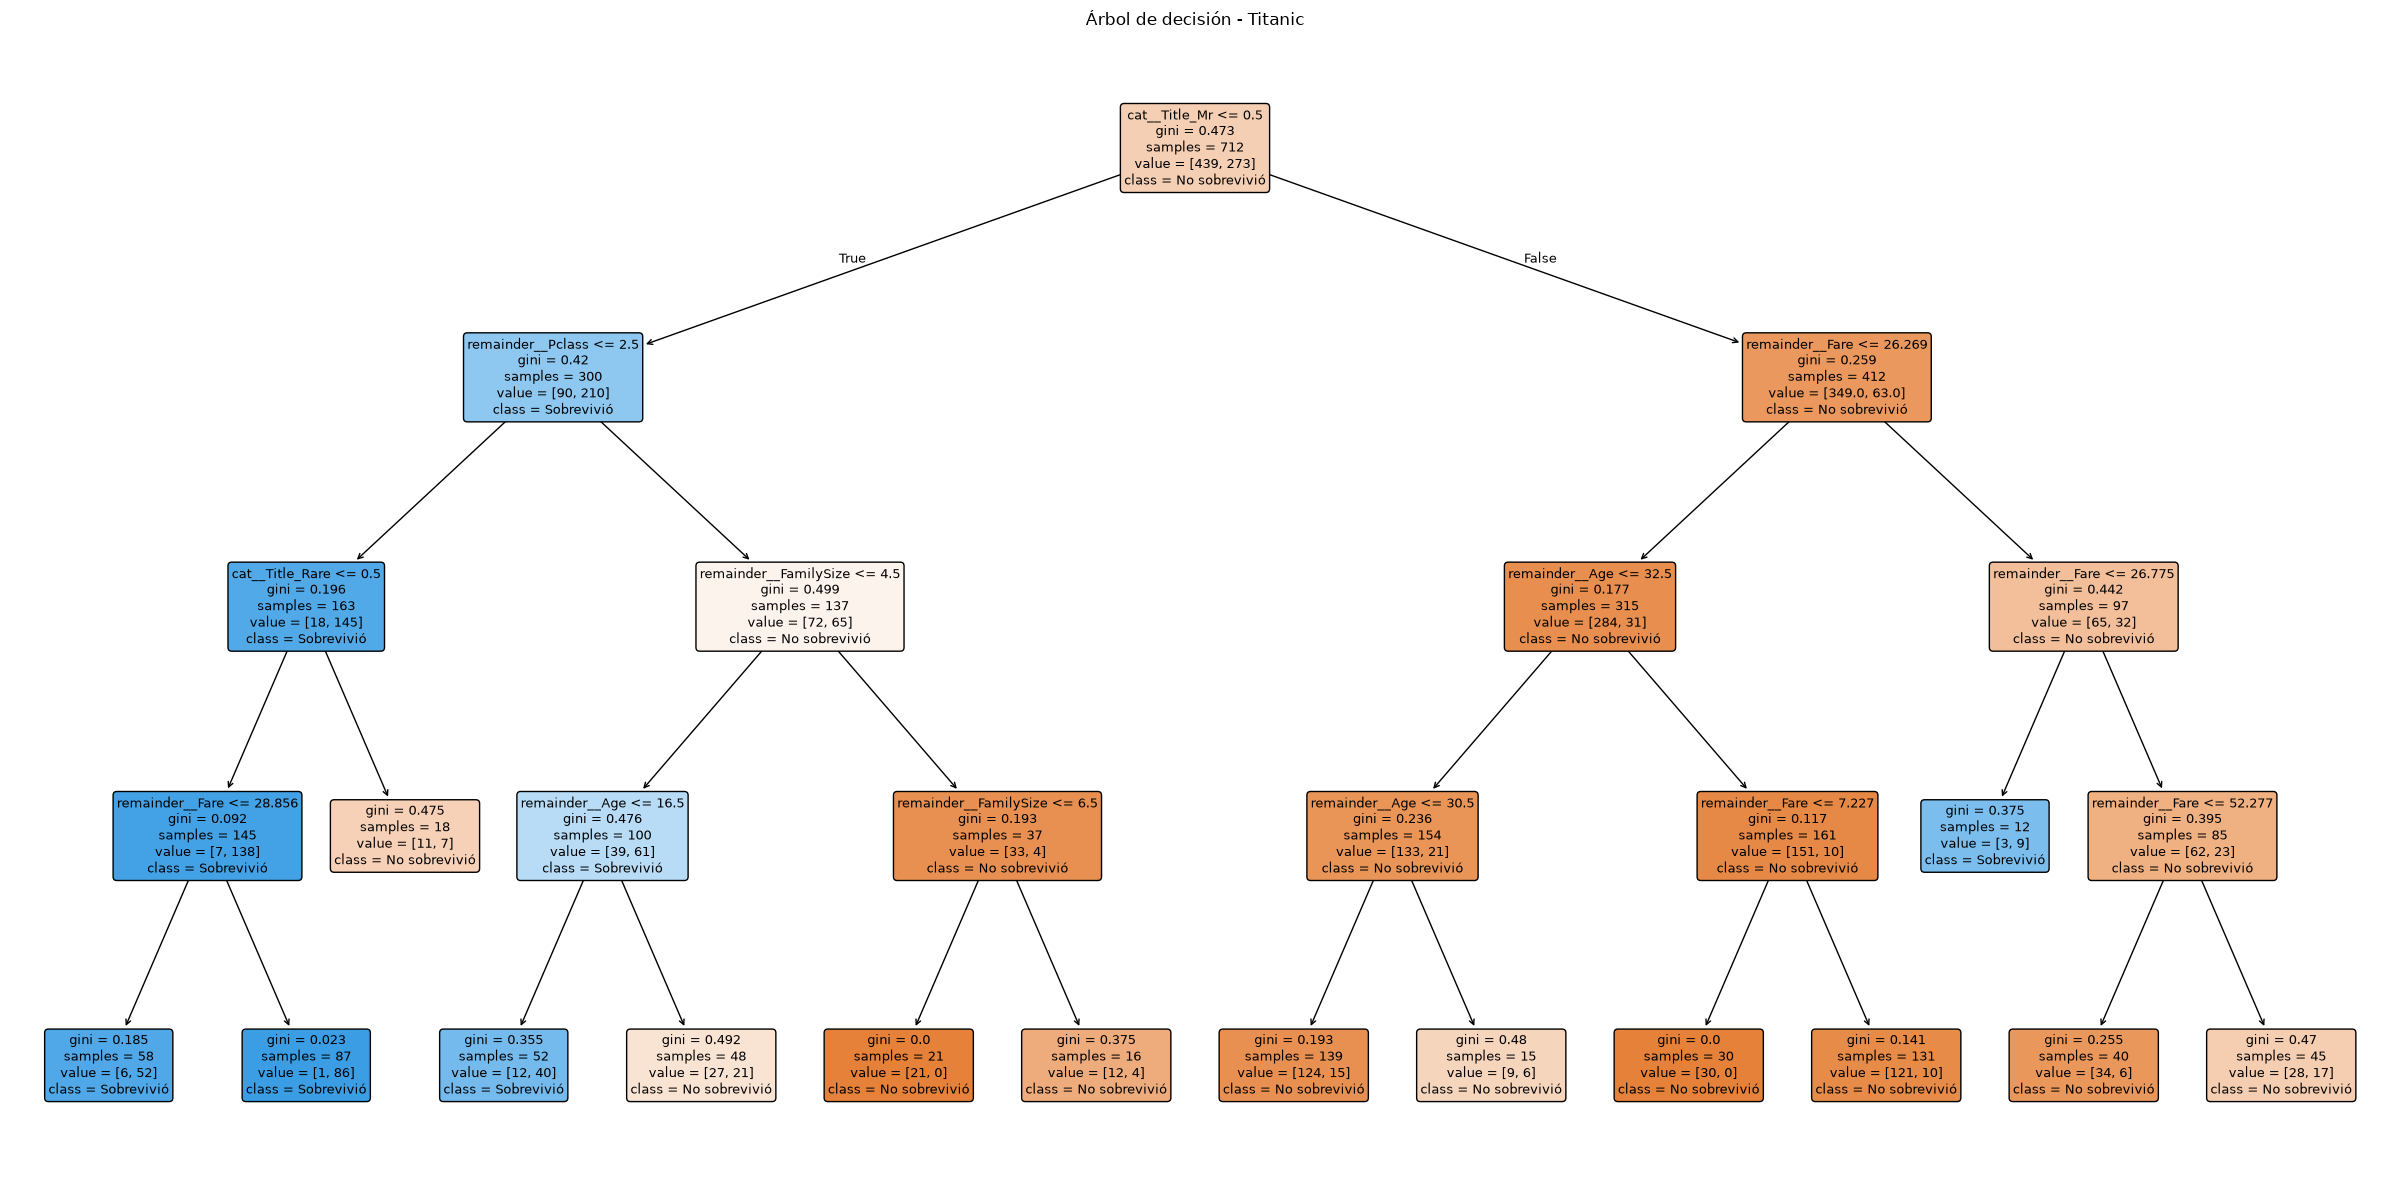

In [84]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    decision_tree,
    feature_names=preprocessor.get_feature_names_out(),
    class_names=['No sobrevivió', 'Sobrevivió'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Árbol de decisión - Titanic')
plt.tight_layout()
plt.show()

### Ejemplo de inferencia sobre un pasajero

In [90]:
# Seleccionamos un pasajero del conjunto de validación
sample_position = 0

# Extraemos sus características procesadas
sample = X_val_processed[sample_position:sample_position + 1]

# Realizamos la predicción
prediction = decision_tree.predict(sample)[0]

# Consultamos el valor real
real_value = y_val.iloc[sample_position]

print('Características originales del pasajero:')
display(X_val.iloc[[sample_position]])

print(f'Valor real: {"Sobrevivió" if real_value == 1 else "No sobrevivió"}')
print(f'Predicción: {"Sobrevivió" if prediction == 1 else "No sobrevivió"}')

Características originales del pasajero:


,Pclass,Sex,Age,AgeGroup,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title
565,3,0,24.0,Young Adult,2,0,24.15,S,3,0,Mr


Valor real: No sobrevivió
Predicción: No sobrevivió


Nodos recorridos: [ 0 14 15 16 17]
Hoja final: 17


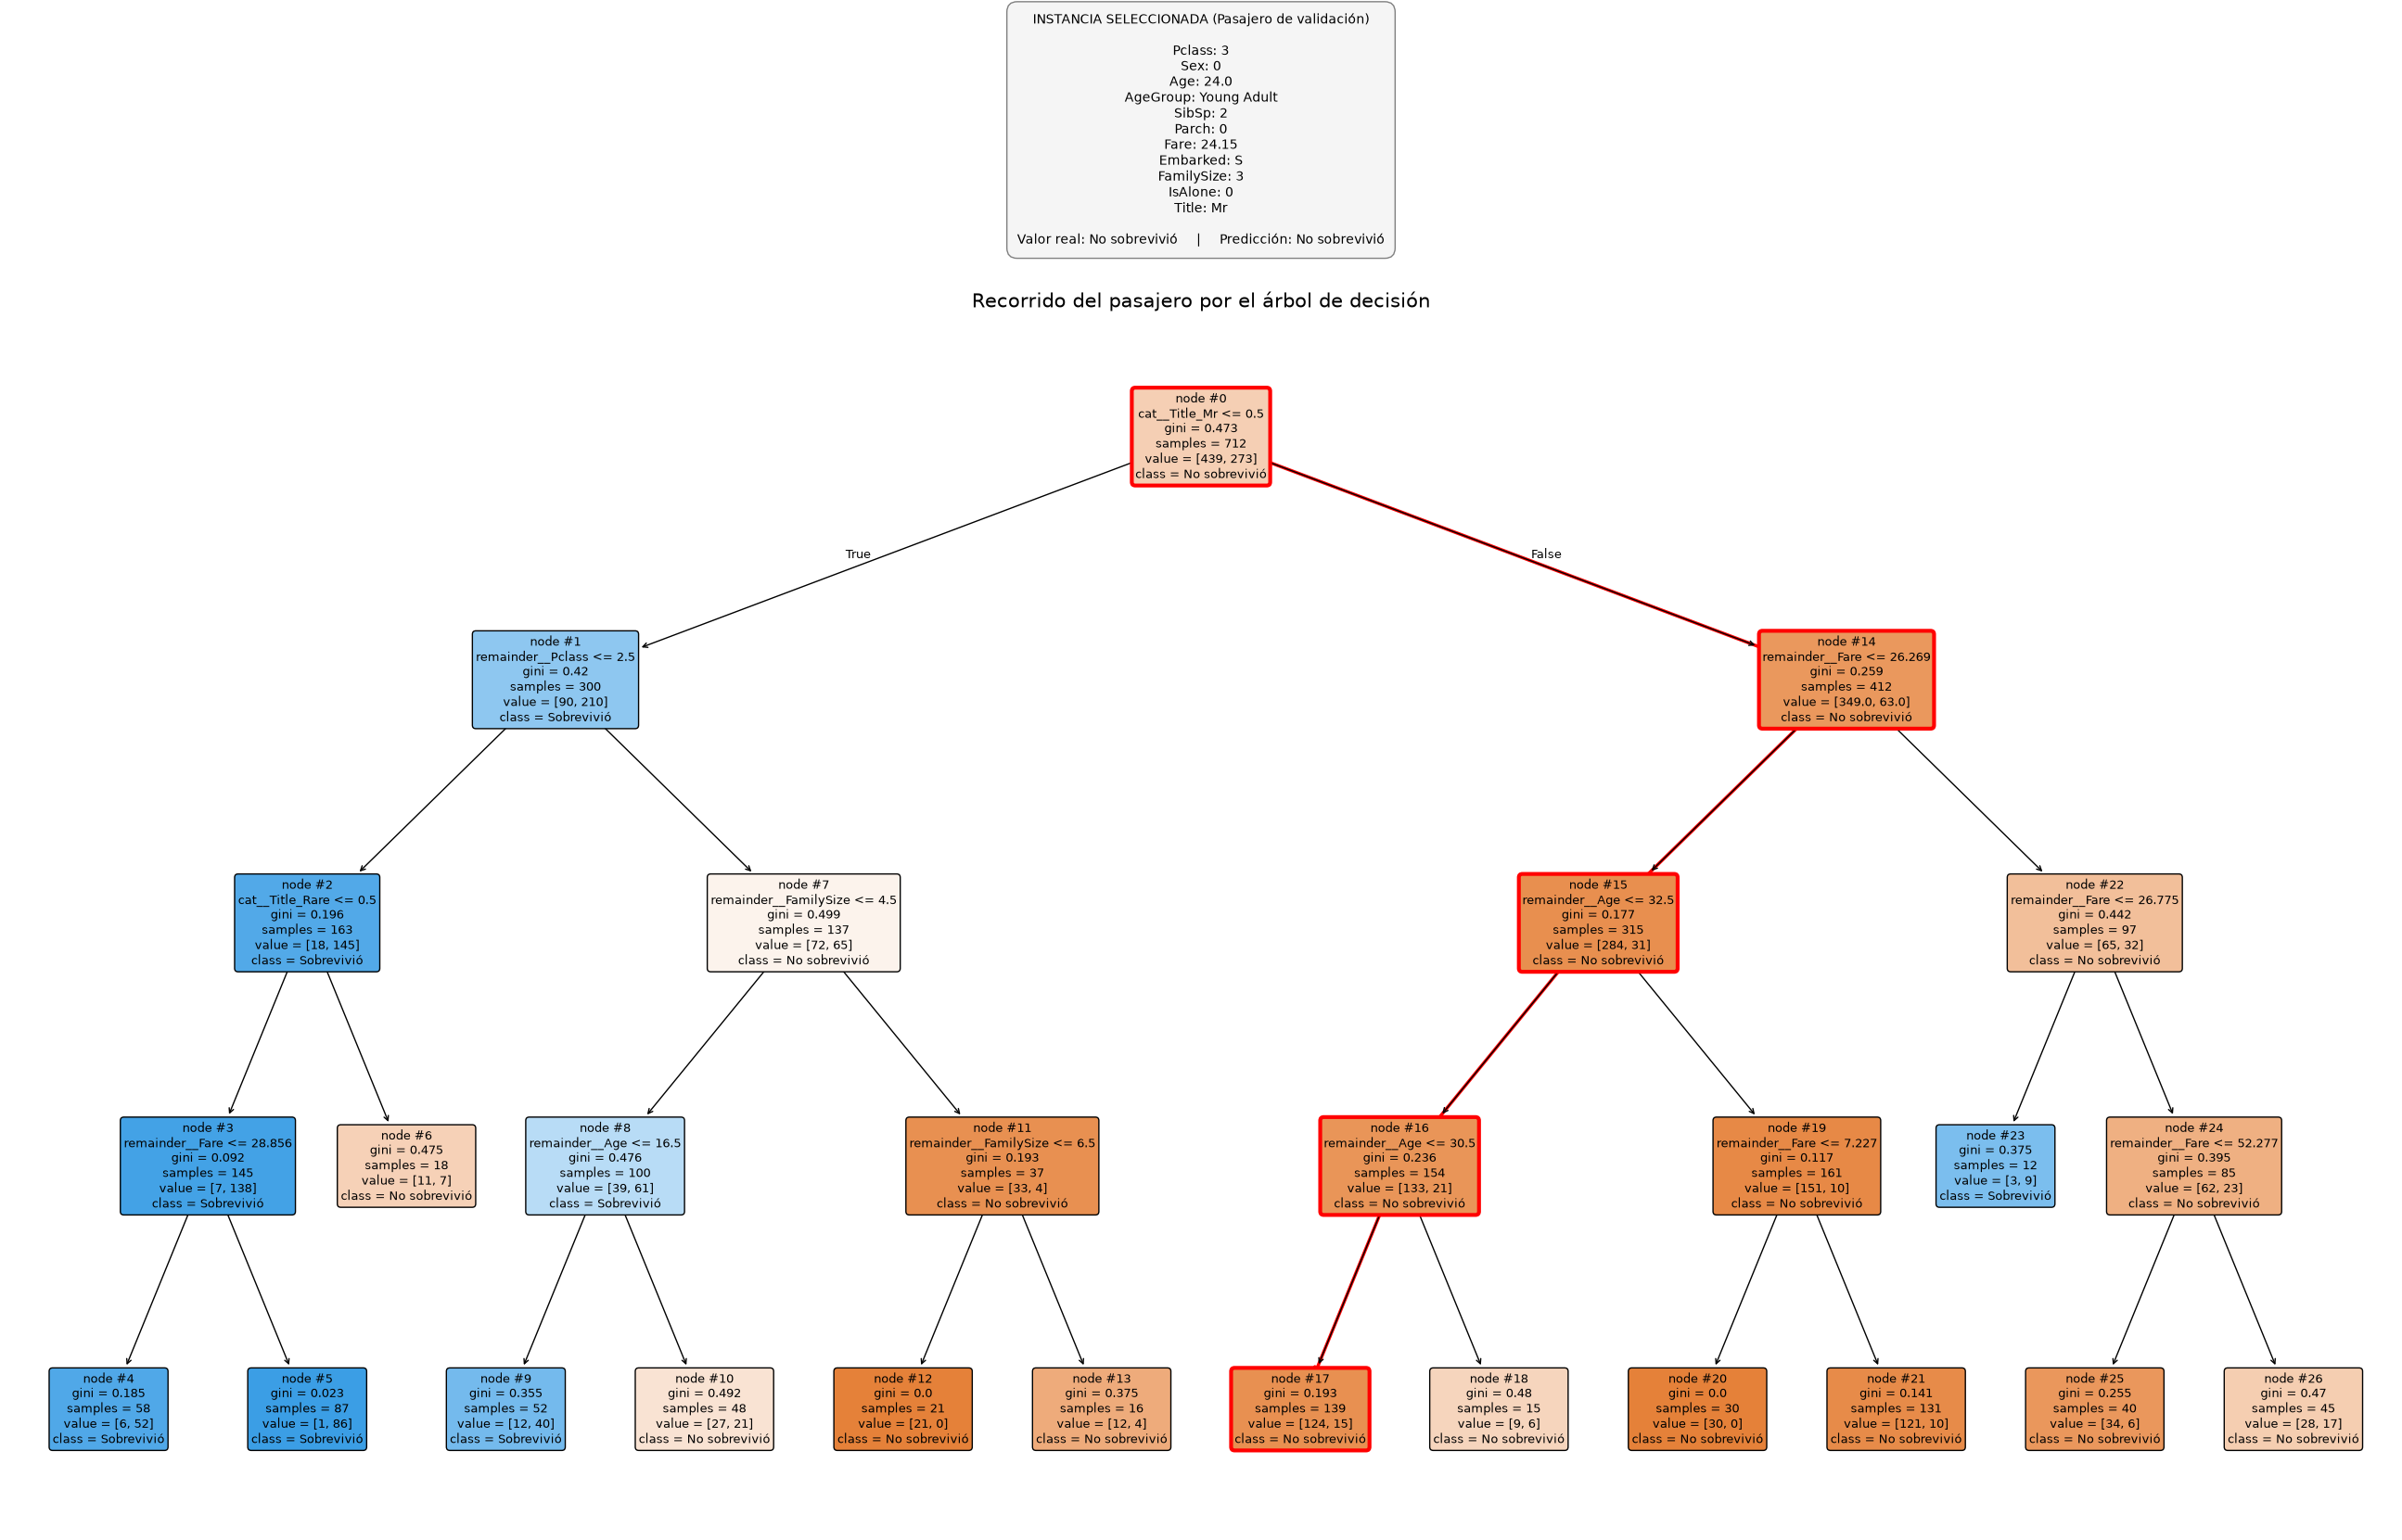

In [ ]:
import re

# Obtenemos los identificadores de los nodos visitados
node_indicator = decision_tree.decision_path(sample)
visited_nodes = node_indicator.indices

# Identificamos la hoja final
leaf_node = decision_tree.apply(sample)[0]

print('Nodos recorridos:', visited_nodes)
print('Hoja final:', leaf_node)

# Creamos una figura con dos zonas: información del pasajero y árbol
fig = plt.figure(figsize=(26, 17))
gs = fig.add_gridspec(2, 1, height_ratios=[1, 5])

ax_info = fig.add_subplot(gs[0])
ax_tree = fig.add_subplot(gs[1])

# --------------------------------------------------
# 1. Información completa del pasajero
# --------------------------------------------------

passenger_info = X_val.iloc[sample_position]

info_text = '\n'.join(
    f'{feature}: {value}'
    for feature, value in passenger_info.items()
)

ax_info.axis('off')

ax_info.text(
    0.5, 0.5,
    f'INSTANCIA SELECCIONADA (Pasajero de validación)\n\n{info_text}\n\n'
    f'Valor real: {"Sobrevivió" if real_value == 1 else "No sobrevivió"}'
    f'     |     Predicción: {"Sobrevivió" if prediction == 1 else "No sobrevivió"}',
    ha='center',
    va='center',
    fontsize=10,
    bbox=dict(boxstyle='round,pad=0.8', facecolor='whitesmoke', edgecolor='gray')
)

# --------------------------------------------------
# 2. Visualización del árbol
# --------------------------------------------------

artists = plot_tree(
    decision_tree,
    feature_names=preprocessor.get_feature_names_out(),
    class_names=['No sobrevivió', 'Sobrevivió'],
    filled=True,
    rounded=True,
    node_ids=True,
    fontsize=9,
    ax=ax_tree
)

# Asociamos cada identificador de nodo con su elemento gráfico
node_artists = {}

for artist in artists:
    match = re.search(r'node #(\d+)', artist.get_text())
    if match:
        node_id = int(match.group(1))
        node_artists[node_id] = artist

# Resaltamos los nodos recorridos
for node_id in visited_nodes:
    bbox = node_artists[node_id].get_bbox_patch()
    bbox.set_edgecolor('red')
    bbox.set_linewidth(3)

# Resaltamos las ramas recorridas
for parent, child in zip(visited_nodes[:-1], visited_nodes[1:]):
    parent_pos = node_artists[parent].get_position()
    child_pos = node_artists[child].get_position()

    ax_tree.annotate(
        '',
        xy=child_pos,
        xytext=parent_pos,
        arrowprops=dict(
            arrowstyle='->',
            color='red',
            linewidth=2.5,
            shrinkA=28,
            shrinkB=28
        ),
        zorder=10
    )

ax_tree.set_title('Recorrido del pasajero por el árbol de decisión', fontsize=15)

plt.tight_layout()
plt.show()

###  Evaluación del modelo

Una vez entrenado el árbol, vamos a comprobar cómo se comporta ante observaciones que no ha utilizado durante el entrenamiento.

Para ello, utilizaremos el conjunto de validación (`X_val_processed`), sobre el que realizaremos las predicciones mediante el método `predict()`.

Posteriormente, evaluaremos los resultados utilizando diferentes métricas:

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** proporción de predicciones positivas que realmente pertenecen a la clase positiva.
- **Recall:** proporción de pasajeros que sobrevivieron y que el modelo ha conseguido identificar correctamente.
- **F1-score:** media armónica entre precision y recall.

También utilizaremos la matriz de confusión para analizar los aciertos y errores del modelo en cada clase.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predicciones sobre el conjunto de validación
y_pred = decision_tree.predict(X_val_processed)

# Accuracy
print(f'Accuracy: {accuracy_score(y_val, y_pred):.4f}')

# Informe de clasificación
print('\nClassification Report:')
print(classification_report(y_val, y_pred))

# Matriz de confusión
print('\nConfusion Matrix:')
print(confusion_matrix(y_val, y_pred))

Accuracy: 0.8268

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.93      0.87       110
           1       0.85      0.67      0.75        69

    accuracy                           0.83       179
   macro avg       0.83      0.80      0.81       179
weighted avg       0.83      0.83      0.82       179


Confusion Matrix:
[[102   8]
 [ 23  46]]


Podemos hacer estos mismos cálculos sobre el conjunto de entrenamiento, para poder comparar las métricas y ver si tenemos overfitting

In [87]:
# Predicciones sobre el conjunto de validación
y_train_pred = decision_tree.predict(X_train_processed)

# Accuracy
print(f'Accuracy: {accuracy_score(y_train, y_train_pred):.4f}')

# Informe de clasificación
print('\nClassification Report:')
print(classification_report(y_train, y_train_pred))

# Matriz de confusión
print('\nConfusion Matrix:')
print(confusion_matrix(y_train, y_train_pred))

Accuracy: 0.8483

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.95      0.89       439
           1       0.89      0.68      0.78       273

    accuracy                           0.85       712
   macro avg       0.86      0.82      0.83       712
weighted avg       0.85      0.85      0.84       712


Confusion Matrix:
[[417  22]
 [ 86 187]]


Los resultados muestran que el árbol de decisión obtiene un **accuracy del 82,68 %**, es decir, clasifica correctamente aproximadamente 8 de cada 10 pasajeros del conjunto de validación.

Si analizamos las métricas por clase:

- **Clase 0 (no sobrevivió):** el modelo obtiene un *recall* del 93 %, identificando correctamente a 102 de los 110 pasajeros que no sobrevivieron. Por tanto, funciona bastante bien identificando esta clase.
- **Clase 1 (sobrevivió):** obtiene un *recall* del 67 %, identificando correctamente a 46 de los 69 pasajeros que sobrevivieron. Esto significa que deja sin detectar a 23 supervivientes.

En cuanto a la matriz de confusión, observamos que el modelo realiza **148 predicciones correctas de 179**. Sin embargo, comete 31 errores: 8 falsos positivos y 23 falsos negativos.

En definitiva, el modelo presenta un rendimiento inicial bastante bueno, aunque muestra una mayor facilidad para identificar a los pasajeros que no sobrevivieron que a los que sí lo hicieron. Esto será interesante tenerlo en cuenta al comparar este modelo con los siguientes.

### Comparación entre entrenamiento y validación

Una forma de evaluar si nuestro modelo generaliza correctamente es comparar sus resultados sobre los datos utilizados durante el entrenamiento y sobre los datos de validación.

Si el modelo obtiene resultados muy buenos en entrenamiento, pero considerablemente peores en validación, podría estar sufriendo **sobreajuste (*overfitting*)**: ha aprendido demasiado bien las particularidades de los datos de entrenamiento, pero no consigue generalizar igual de bien a nuevos pasajeros.

Vamos a comparar las principales métricas y las matrices de confusión de ambos conjuntos.

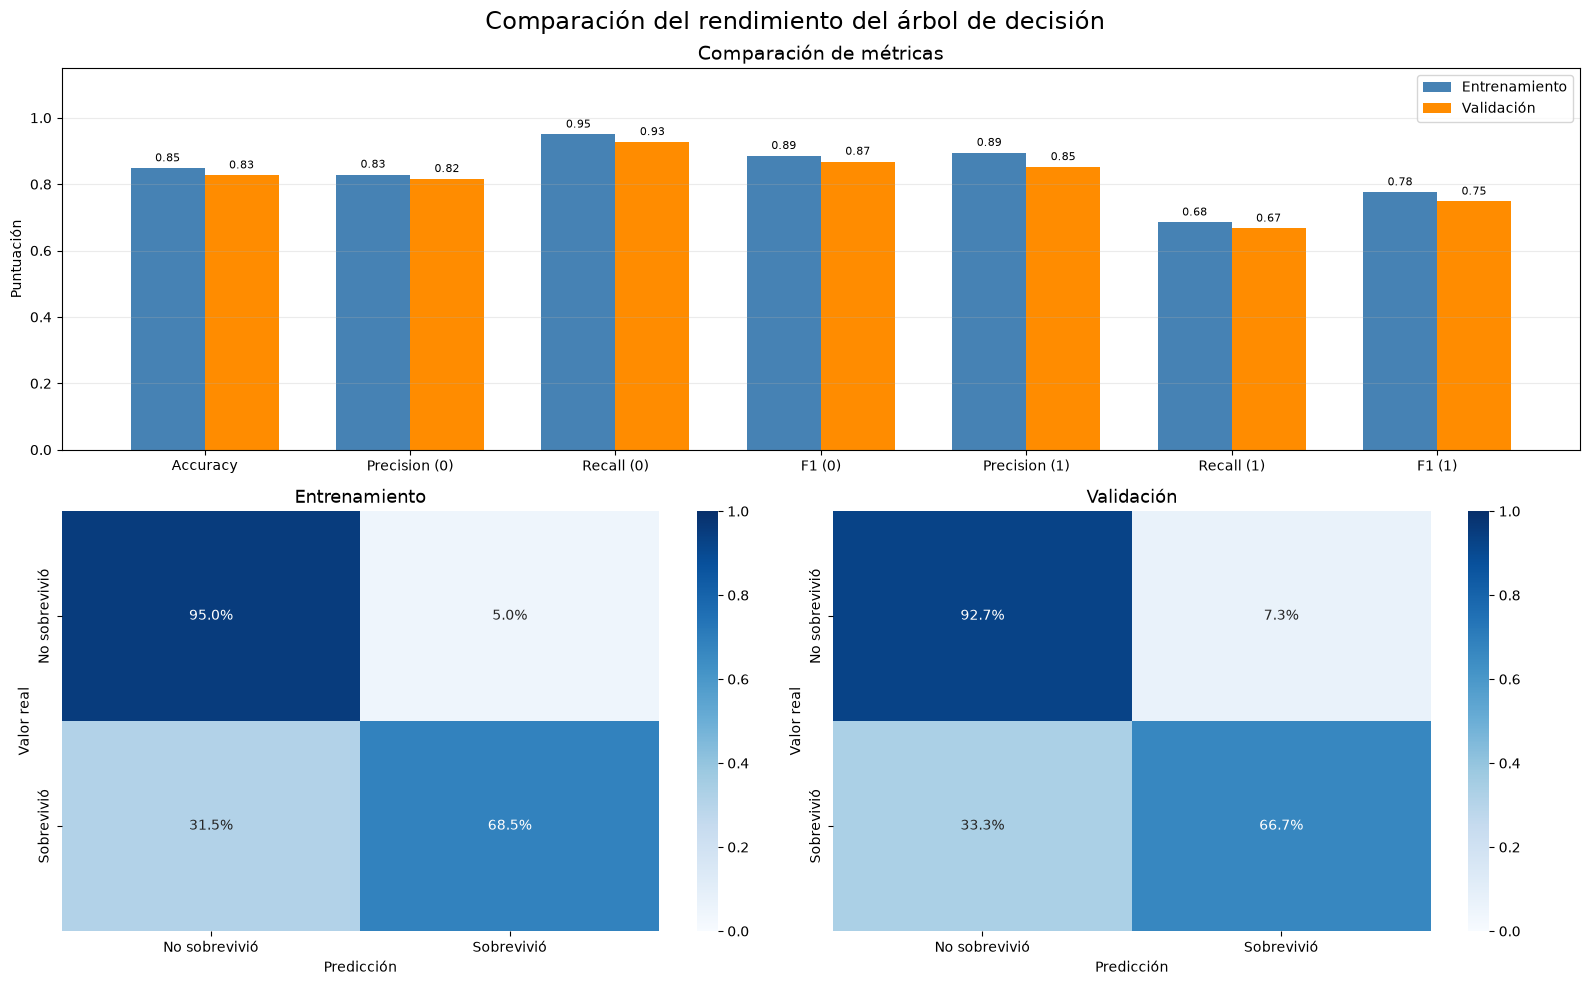

In [99]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np

# Obtenemos las métricas directamente de las predicciones existentes
train_report = classification_report(
    y_train, y_train_pred, output_dict=True, zero_division=0
)

val_report = classification_report(
    y_val, y_pred, output_dict=True, zero_division=0
)

# Métricas que queremos comparar
metric_names = [
    'Accuracy',
    'Precision (0)', 'Recall (0)', 'F1 (0)',
    'Precision (1)', 'Recall (1)', 'F1 (1)'
]

train_scores = [
    accuracy_score(y_train, y_train_pred),
    train_report['0']['precision'],
    train_report['0']['recall'],
    train_report['0']['f1-score'],
    train_report['1']['precision'],
    train_report['1']['recall'],
    train_report['1']['f1-score']
]

val_scores = [
    accuracy_score(y_val, y_pred),
    val_report['0']['precision'],
    val_report['0']['recall'],
    val_report['0']['f1-score'],
    val_report['1']['precision'],
    val_report['1']['recall'],
    val_report['1']['f1-score']
]

# Matrices de confusión normalizadas
cm_train = confusion_matrix(y_train, y_train_pred, normalize='true')
cm_val = confusion_matrix(y_val, y_pred, normalize='true')

# --------------------------------------------------
# REPRESENTACIÓN GRÁFICA
# --------------------------------------------------

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1])

ax_metrics = fig.add_subplot(gs[0, :])
ax_train = fig.add_subplot(gs[1, 0])
ax_val = fig.add_subplot(gs[1, 1])

# Comparación de métricas
x = np.arange(len(metric_names))
width = 0.36

bars_train = ax_metrics.bar(
    x - width/2, train_scores, width,
    label='Entrenamiento', color='steelblue'
)

bars_val = ax_metrics.bar(
    x + width/2, val_scores, width,
    label='Validación', color='darkorange'
)

ax_metrics.bar_label(bars_train, fmt='%.2f', padding=3, fontsize=8)
ax_metrics.bar_label(bars_val, fmt='%.2f', padding=3, fontsize=8)

ax_metrics.set_title('Comparación de métricas', fontsize=14)
ax_metrics.set_ylabel('Puntuación')
ax_metrics.set_xticks(x)
ax_metrics.set_xticklabels(metric_names)
ax_metrics.set_ylim(0, 1.15)
ax_metrics.legend()
ax_metrics.grid(axis='y', alpha=0.25)

# Matriz de confusión: entrenamiento
sns.heatmap(
    cm_train, annot=True, fmt='.1%', cmap='Blues',
    vmin=0, vmax=1,
    xticklabels=['No sobrevivió', 'Sobrevivió'],
    yticklabels=['No sobrevivió', 'Sobrevivió'],
    ax=ax_train
)

ax_train.set_title('Entrenamiento', fontsize=13)
ax_train.set_xlabel('Predicción')
ax_train.set_ylabel('Valor real')

# Matriz de confusión: validación
sns.heatmap(
    cm_val, annot=True, fmt='.1%', cmap='Blues',
    vmin=0, vmax=1,
    xticklabels=['No sobrevivió', 'Sobrevivió'],
    yticklabels=['No sobrevivió', 'Sobrevivió'],
    ax=ax_val
)

ax_val.set_title('Validación', fontsize=13)
ax_val.set_xlabel('Predicción')
ax_val.set_ylabel('Valor real')

plt.suptitle('Comparación del rendimiento del árbol de decisión', fontsize=17)
plt.tight_layout()
plt.show()


#### Matriz de confusión

La **matriz de confusión** (*confusion matrix*) es una herramienta que permite evaluar el rendimiento de un modelo de clasificación comparando las predicciones realizadas con los valores reales.

En nuestro caso, queremos predecir si un pasajero sobrevivió (`1`) o no sobrevivió (`0`). La matriz recoge el número de predicciones correctas e incorrectas para cada clase.

En un problema de clasificación binaria aparecen cuatro resultados posibles:

| | **Predicción: No sobrevivió (0)** | **Predicción: Sobrevivió (1)** |
|:---|:---:|:---:|
| **Real: No sobrevivió (0)** | Verdadero negativo (TN) | Falso positivo (FP) |
| **Real: Sobrevivió (1)** | Falso negativo (FN) | Verdadero positivo (TP) |

- **Verdaderos negativos (TN):** pasajeros que no sobrevivieron y que el modelo clasificó correctamente.
- **Falsos positivos (FP):** pasajeros que no sobrevivieron, pero que el modelo predijo que sí lo hicieron.
- **Falsos negativos (FN):** pasajeros que sobrevivieron, pero que el modelo predijo que no lo hicieron.
- **Verdaderos positivos (TP):** pasajeros que sobrevivieron y que el modelo clasificó correctamente.

La diagonal principal contiene las predicciones correctas (TN y TP), mientras que las otras dos celdas recogen los errores del modelo (FP y FN).

Esta matriz nos permite ir más allá de una única métrica como el *accuracy*, ya que muestra qué tipos de errores está cometiendo el clasificador y sobre qué clase.


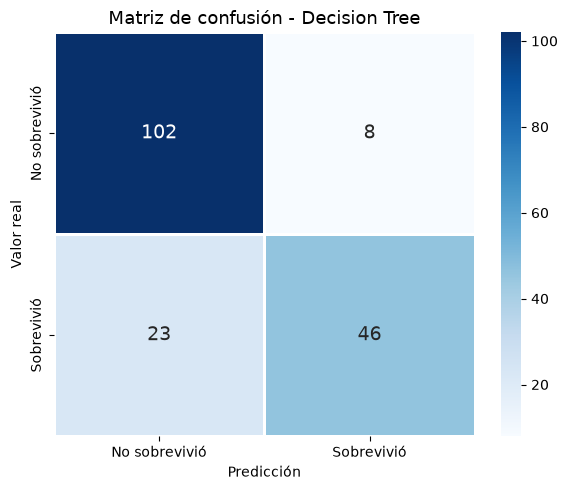

In [82]:
from sklearn.metrics import confusion_matrix

# Calculamos la matriz de confusión
cm = confusion_matrix(y_val, y_pred)

# Representación gráfica
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1,
    linecolor='white',
    xticklabels=['No sobrevivió', 'Sobrevivió'],
    yticklabels=['No sobrevivió', 'Sobrevivió'],
    annot_kws={'size': 14}
)

plt.title('Matriz de confusión - Decision Tree', fontsize=13)
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.tight_layout()
plt.show()



### ¿Qué es Random Forest?

**Random Forest** (bosque aleatorio) es un algoritmo de aprendizaje supervisado que permite resolver problemas de clasificación y regresión. Se encuentra dentro de una familia de métodos conocida como **Ensemble Learning (aprendizaje en conjunto)**.

La idea del *Ensemble Learning* consiste en combinar varios modelos de aprendizaje automático para obtener una predicción conjunta. En lugar de confiar en un único modelo, se utilizan varios modelos que trabajan conjuntamente, aprovechando sus diferentes perspectivas para conseguir resultados más robustos y fiables.

Existen diferentes estrategias de *Ensemble Learning*. Random Forest utiliza una de ellas, denominada **Bagging (Bootstrap Aggregating)**, que consiste en entrenar múltiples modelos utilizando diferentes muestras aleatorias de los datos de entrenamiento y combinar posteriormente sus predicciones.

En concreto, Random Forest funciona de la siguiente manera:

1. El algoritmo genera diferentes conjuntos de datos mediante muestreo aleatorio con reemplazo (*Bootstrap*).
2. Con cada uno de esos conjuntos construye un árbol de decisión.
3. Durante la construcción de cada árbol, también se selecciona aleatoriamente un subconjunto de variables para realizar las divisiones.
4. Cada árbol realiza su propia predicción.
5. Finalmente, se combinan todas las predicciones. En clasificación, la clase más votada será la predicción final del modelo.

Por ejemplo, imaginemos que construimos un bosque con 100 árboles para predecir si un pasajero sobrevivió:

- 75 árboles predicen que sobrevivió.
- 25 árboles predicen que no sobrevivió.

La predicción final será que el pasajero sobrevivió, puesto que es la clase que ha obtenido más votos.

Al combinar múltiples árboles, Random Forest suele conseguir modelos más robustos y menos sensibles a las particularidades de los datos de entrenamiento que un único árbol de decisión.

![Random forest](https://images.openai.com/static-rsc-4/Za3lXa_Hly0d9rMj7wRLc1Lzvor9dodngYIwTbtqpso216P-EB7FGsuS1yWKbiNVSv0-YBeH6EXWNZ2dYEhprADarRombQ6hZP4DdZ5DCC0SAy0F3Fubjz5KkJ0v0pn0RzHPRKcMa3IbzZrgesVkEGdOwYyfPeVoLuBN6VXgy7HPMfaczeDtl67INhTiF1uf?purpose=fullsize)


### Definición del modelo

Los principales hiperparámetros que vamos a configurar son:

- **`n_estimators`:** número de árboles que formarán el bosque. Cuantos más árboles utilicemos, mayor será el número de predicciones que se combinarán.
- **`criterion`:** criterio utilizado para medir la calidad de las divisiones de cada árbol. Utilizaremos el índice Gini.
- **`max_depth`:** profundidad máxima permitida para cada árbol. Limitarla ayuda a evitar árboles excesivamente complejos.
- **`min_samples_leaf`:** número mínimo de observaciones que debe contener una hoja. Evita que los árboles generen decisiones demasiado específicas.
- **`max_features`:** número de variables que se consideran aleatoriamente en cada división. Esto introduce diversidad entre los árboles.
- **`random_state`:** permite reproducir los mismos resultados en diferentes ejecuciones.

Vamos a comenzar con una configuración inicial y posteriormente podremos estudiar si modificar estos parámetros mejora el rendimiento.

In [113]:
from sklearn.ensemble import RandomForestClassifier

# Creación del modelo Random Forest
random_forest = RandomForestClassifier(
    n_estimators=200,
    criterion='gini',
    max_depth=10,
    min_samples_leaf=4,
    max_features='sqrt',
    random_state=42
)

# Entrenamiento del modelo
random_forest.fit(X_train_processed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap


### Evaluación del modelo

Una vez entrenado el bosque aleatorio, vamos a evaluar su rendimiento sobre el conjunto de validación.

Para ello utilizaremos las mismas métricas que en el árbol de decisión:

- **Accuracy:** porcentaje total de predicciones correctas.
- **Precision:** proporción de predicciones positivas que realmente pertenecen a esa clase.
- **Recall:** proporción de observaciones de una clase que el modelo consigue identificar correctamente.
- **F1-score:** combina Precision y Recall en una única métrica.

In [114]:
# Predicciones sobre el conjunto de validación
y_pred_rf = random_forest.predict(X_val_processed)

# Accuracy
print(f'Accuracy: {accuracy_score(y_val, y_pred_rf):.4f}')

# Informe de clasificación
print('\nClassification Report:')
print(classification_report(y_val, y_pred_rf))

# Matriz de confusión
print('\nConfusion Matrix:')
print(confusion_matrix(y_val, y_pred_rf))


Accuracy: 0.8436

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.92      0.88       110
           1       0.85      0.72      0.78        69

    accuracy                           0.84       179
   macro avg       0.84      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179


Confusion Matrix:
[[101   9]
 [ 19  50]]


### Comparación con el conjunto de entrenamiento

Al igual que hicimos con el árbol de decisión, también vamos a evaluar el modelo sobre los datos utilizados durante su entrenamiento.

Esta comparación nos permitirá comprobar si el modelo presenta diferencias importantes entre ambos conjuntos.

Si el rendimiento sobre entrenamiento es considerablemente superior al de validación, podríamos estar ante un problema de sobreajuste (*overfitting*).

In [116]:
# Predicciones sobre el conjunto de entrenamiento
y_train_pred_rf = random_forest.predict(X_train_processed)

# Accuracy
print(f'Accuracy: {accuracy_score(y_train, y_train_pred_rf):.4f}')

# Informe de clasificación
print('\nClassification Report:')
print(classification_report(y_train, y_train_pred_rf))

# Matriz de confusión
print('\nConfusion Matrix:')
print(confusion_matrix(y_train, y_train_pred_rf))


Accuracy: 0.8694

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.94      0.90       439
           1       0.89      0.75      0.82       273

    accuracy                           0.87       712
   macro avg       0.88      0.85      0.86       712
weighted avg       0.87      0.87      0.87       712


Confusion Matrix:
[[414  25]
 [ 68 205]]


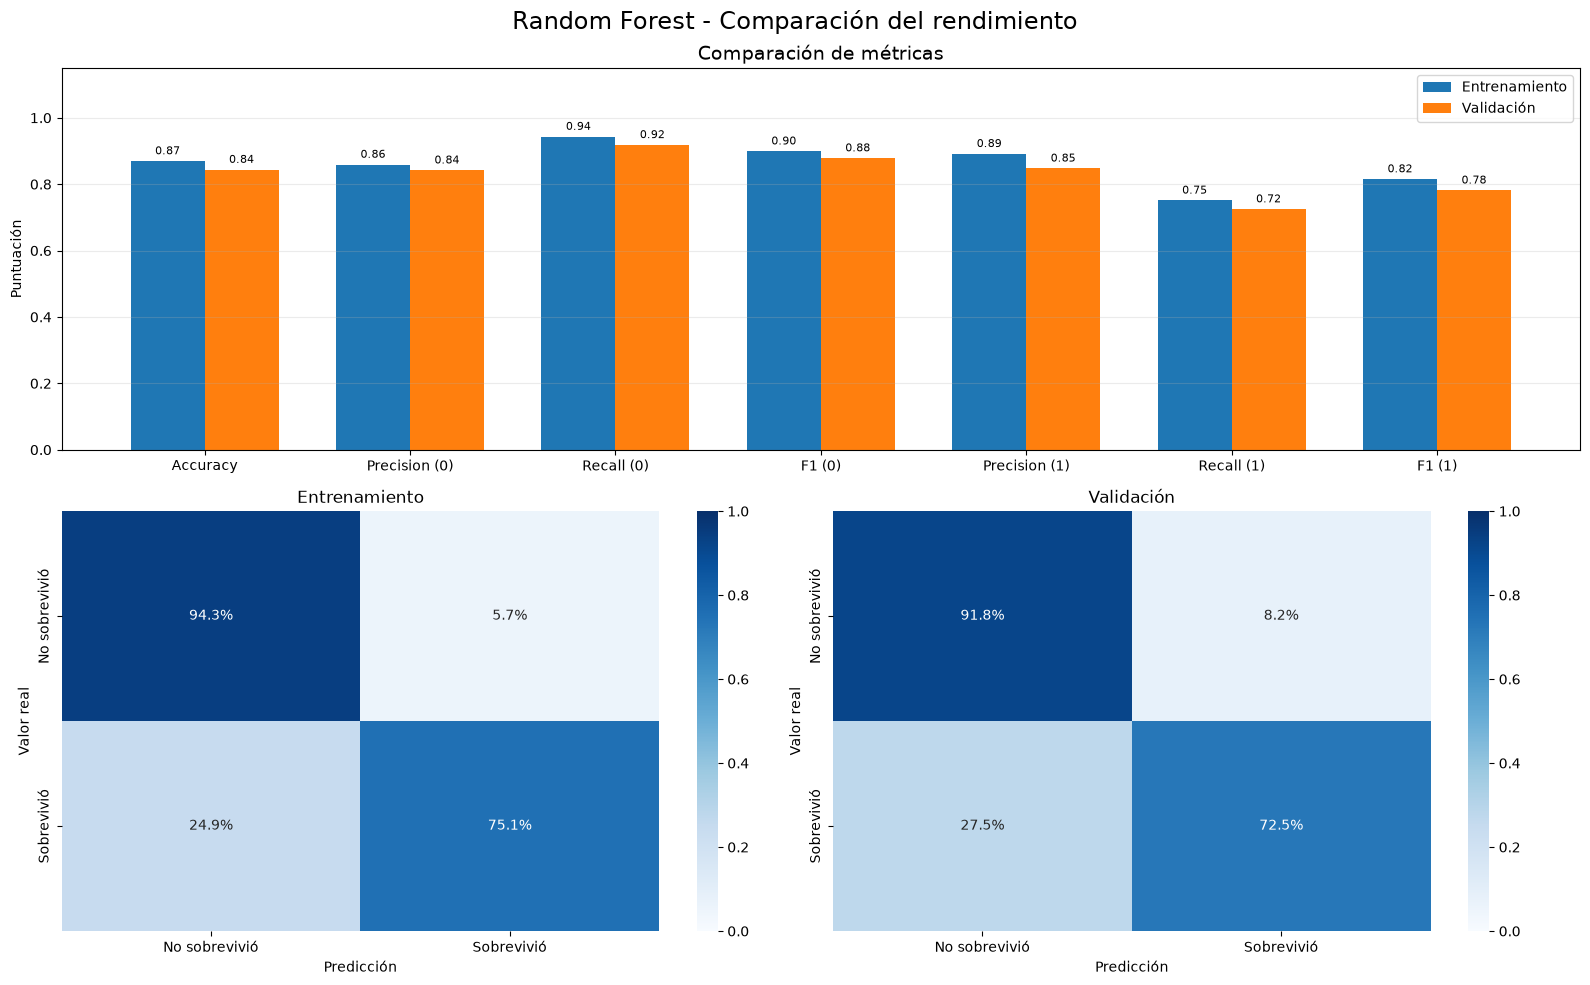

In [117]:
# Informes de clasificación
train_report_rf = classification_report(
    y_train, y_train_pred_rf, output_dict=True
)

val_report_rf = classification_report(
    y_val, y_pred_rf, output_dict=True
)

# Métricas
metric_names = [
    'Accuracy',
    'Precision (0)', 'Recall (0)', 'F1 (0)',
    'Precision (1)', 'Recall (1)', 'F1 (1)'
]

train_scores = [
    accuracy_score(y_train, y_train_pred_rf),
    train_report_rf['0']['precision'],
    train_report_rf['0']['recall'],
    train_report_rf['0']['f1-score'],
    train_report_rf['1']['precision'],
    train_report_rf['1']['recall'],
    train_report_rf['1']['f1-score']
]

val_scores = [
    accuracy_score(y_val, y_pred_rf),
    val_report_rf['0']['precision'],
    val_report_rf['0']['recall'],
    val_report_rf['0']['f1-score'],
    val_report_rf['1']['precision'],
    val_report_rf['1']['recall'],
    val_report_rf['1']['f1-score']
]

# Matrices de confusión normalizadas
cm_train = confusion_matrix(
    y_train, y_train_pred_rf, normalize='true'
)

cm_val = confusion_matrix(
    y_val, y_pred_rf, normalize='true'
)

# Representación
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1])

ax_metrics = fig.add_subplot(gs[0, :])
ax_train = fig.add_subplot(gs[1, 0])
ax_val = fig.add_subplot(gs[1, 1])

x = np.arange(len(metric_names))
width = 0.36

bars_train = ax_metrics.bar(
    x - width/2, train_scores, width, label='Entrenamiento'
)

bars_val = ax_metrics.bar(
    x + width/2, val_scores, width, label='Validación'
)

ax_metrics.bar_label(bars_train, fmt='%.2f', padding=3, fontsize=8)
ax_metrics.bar_label(bars_val, fmt='%.2f', padding=3, fontsize=8)

ax_metrics.set_title('Comparación de métricas', fontsize=14)
ax_metrics.set_ylabel('Puntuación')
ax_metrics.set_xticks(x)
ax_metrics.set_xticklabels(metric_names)
ax_metrics.set_ylim(0, 1.15)
ax_metrics.legend()
ax_metrics.grid(axis='y', alpha=0.25)

sns.heatmap(
    cm_train, annot=True, fmt='.1%', cmap='Blues',
    vmin=0, vmax=1,
    xticklabels=['No sobrevivió', 'Sobrevivió'],
    yticklabels=['No sobrevivió', 'Sobrevivió'],
    ax=ax_train
)

ax_train.set_title('Entrenamiento')
ax_train.set_xlabel('Predicción')
ax_train.set_ylabel('Valor real')

sns.heatmap(
    cm_val, annot=True, fmt='.1%', cmap='Blues',
    vmin=0, vmax=1,
    xticklabels=['No sobrevivió', 'Sobrevivió'],
    yticklabels=['No sobrevivió', 'Sobrevivió'],
    ax=ax_val
)

ax_val.set_title('Validación')
ax_val.set_xlabel('Predicción')
ax_val.set_ylabel('Valor real')

plt.suptitle('Random Forest - Comparación del rendimiento', fontsize=17)
plt.tight_layout()
plt.show()


### Matriz de confusión 

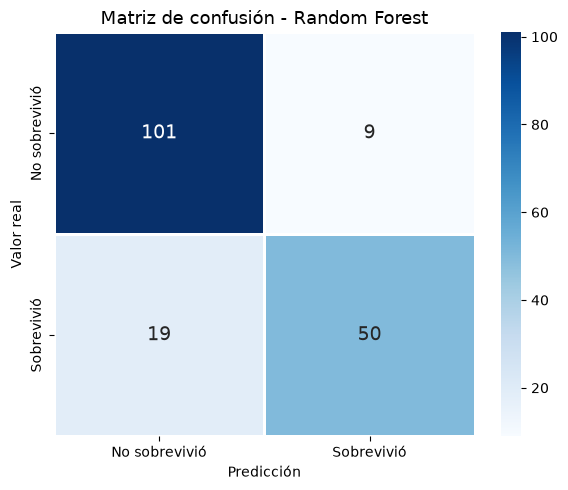

In [118]:

cm = confusion_matrix(y_val, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1,
    linecolor='white',
    xticklabels=['No sobrevivió', 'Sobrevivió'],
    yticklabels=['No sobrevivió', 'Sobrevivió'],
    annot_kws={'size': 14}
)

plt.title('Matriz de confusión - Random Forest', fontsize=13)
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.tight_layout()
plt.show()



### Comparación: Decision Tree vs Random Forest

Una vez entrenados ambos modelos, podemos comparar su rendimiento sobre el conjunto de validación.

No debemos fijarnos únicamente en el *accuracy*, ya que esta métrica no siempre refleja por completo el comportamiento de un clasificador. También resulta interesante analizar:

- **Precision:** de todas las predicciones realizadas para una clase, ¿qué proporción era correcta?
- **Recall:** de todos los pasajeros que realmente pertenecían a una clase, ¿qué proporción ha conseguido identificar el modelo?
- **F1-score:** combina precision y recall en una única métrica.

Realizaremos la comparación tanto para cada clase por separado como mediante los promedios globales (*macro average* y *weighted average*).

De esta forma, podremos observar no solo qué modelo obtiene mejores resultados generales, sino también cuál identifica mejor a los pasajeros que sobrevivieron.


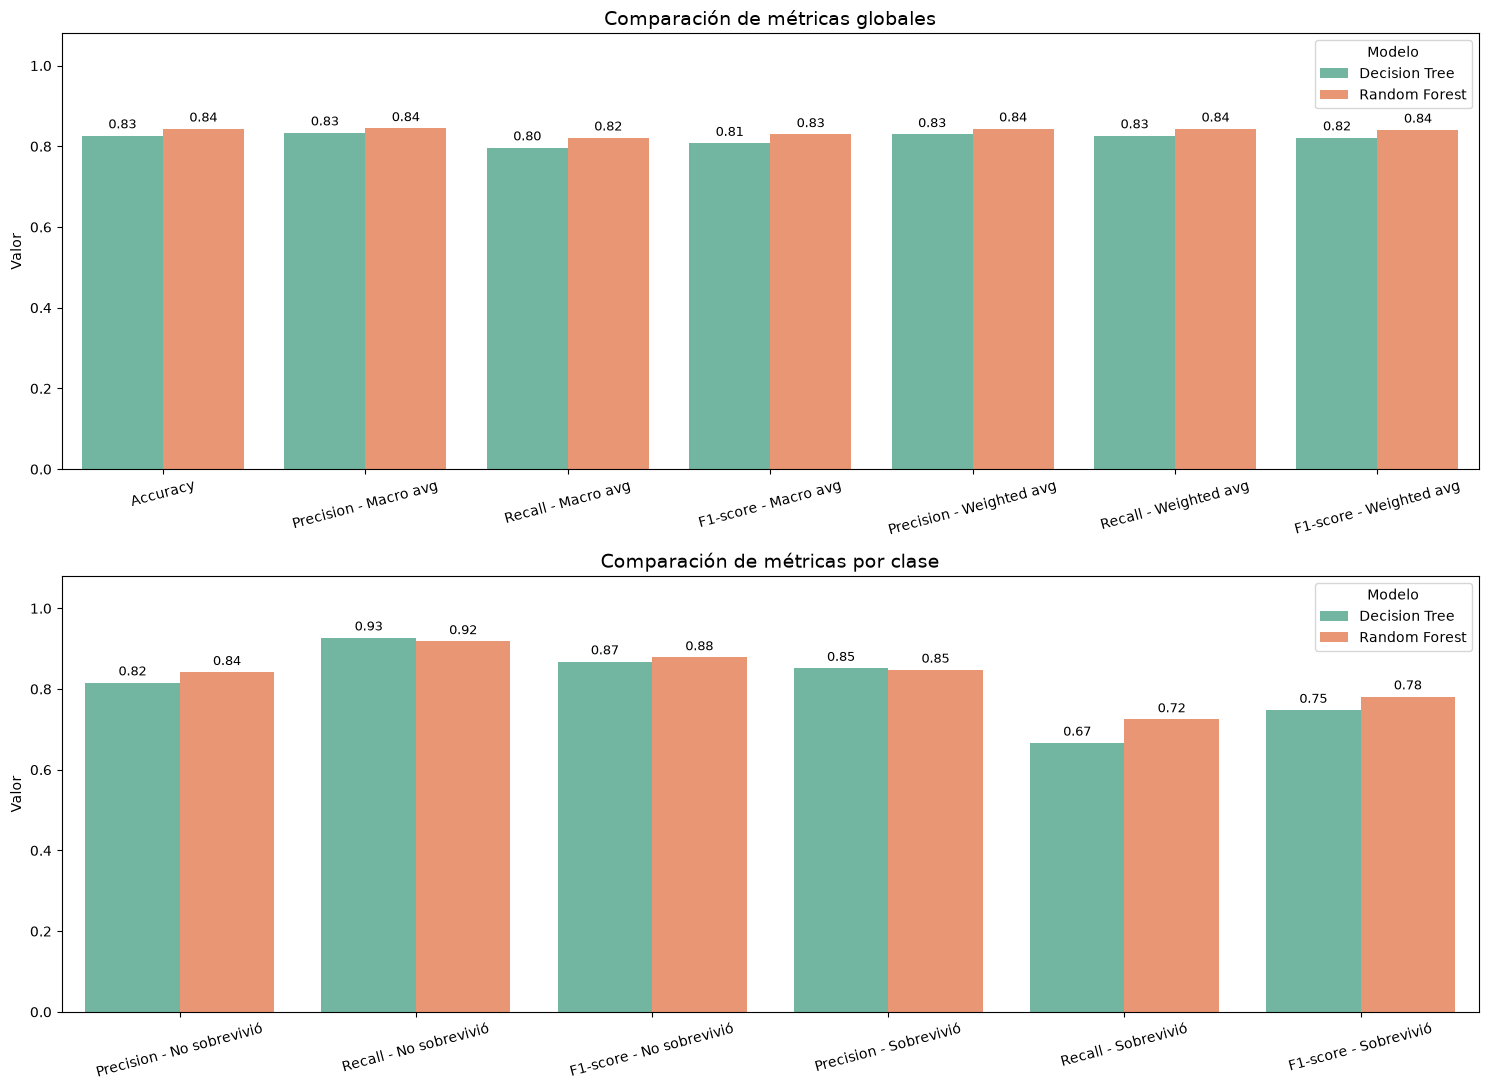

In [119]:
# Obtener predicciones de ambos modelos sobre el conjunto de validación
y_pred_dt = decision_tree.predict(X_val_processed)
y_pred_rf = random_forest.predict(X_val_processed)

# Calcular los informes de clasificación
report_dt = classification_report(
    y_val, y_pred_dt, output_dict=True, zero_division=0
)

report_rf = classification_report(
    y_val, y_pred_rf, output_dict=True, zero_division=0
)

# Preparar los datos para la comparación
class_metrics = []
global_metrics = []

models = {
    'Decision Tree': (y_pred_dt, report_dt),
    'Random Forest': (y_pred_rf, report_rf)
}

for model_name, (predictions, report) in models.items():

    # Accuracy
    global_metrics.append({
        'Modelo': model_name,
        'Métrica': 'Accuracy',
        'Valor': accuracy_score(y_val, predictions)
    })

    # Métricas por clase
    for label, class_name in [('0', 'No sobrevivió'), ('1', 'Sobrevivió')]:
        for metric, metric_name in [
            ('precision', 'Precision'),
            ('recall', 'Recall'),
            ('f1-score', 'F1-score')
        ]:
            class_metrics.append({
                'Modelo': model_name,
                'Métrica': f'{metric_name} - {class_name}',
                'Valor': report[label][metric]
            })

    # Promedios globales
    for average, average_name in [
        ('macro avg', 'Macro avg'),
        ('weighted avg', 'Weighted avg')
    ]:
        for metric, metric_name in [
            ('precision', 'Precision'),
            ('recall', 'Recall'),
            ('f1-score', 'F1-score')
        ]:
            global_metrics.append({
                'Modelo': model_name,
                'Métrica': f'{metric_name} - {average_name}',
                'Valor': report[average][metric]
            })

# Convertir los resultados en DataFrames
class_metrics = pd.DataFrame(class_metrics)
global_metrics = pd.DataFrame(global_metrics)

# Orden de las métricas en los gráficos
global_order = [
    'Accuracy',
    'Precision - Macro avg',
    'Recall - Macro avg',
    'F1-score - Macro avg',
    'Precision - Weighted avg',
    'Recall - Weighted avg',
    'F1-score - Weighted avg'
]

class_order = [
    'Precision - No sobrevivió',
    'Recall - No sobrevivió',
    'F1-score - No sobrevivió',
    'Precision - Sobrevivió',
    'Recall - Sobrevivió',
    'F1-score - Sobrevivió'
]

# Crear los gráficos
fig, axes = plt.subplots(2, 1, figsize=(15, 11))

# Gráfico 1: Métricas globales
sns.barplot(
    data=global_metrics,
    x='Métrica',
    y='Valor',
    hue='Modelo',
    order=global_order,
    palette='Set2',
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title('Comparación de métricas globales', fontsize=14)
axes[0].set_xlabel('')
axes[0].set_ylabel('Valor')
axes[0].set_ylim(0, 1.08)
axes[0].tick_params(axis='x', rotation=15)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f', padding=3, fontsize=9)

axes[0].legend(title='Modelo')

# Gráfico 2: Métricas por clase
sns.barplot(
    data=class_metrics,
    x='Métrica',
    y='Valor',
    hue='Modelo',
    order=class_order,
    palette='Set2',
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title('Comparación de métricas por clase', fontsize=14)
axes[1].set_xlabel('')
axes[1].set_ylabel('Valor')
axes[1].set_ylim(0, 1.08)
axes[1].tick_params(axis='x', rotation=15)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f', padding=3, fontsize=9)

axes[1].legend(title='Modelo')

plt.tight_layout()
plt.show()


Al comparar ambos modelos, observamos que **Random Forest obtiene mejores resultados en la mayoría de las métricas**, aunque las diferencias respecto al árbol de decisión no son especialmente pronunciadas.

La diferencia más destacable aparece en el **Recall**, especialmente en la clase de pasajeros que sobrevivieron (clase 1). Esto indica que Random Forest consigue identificar correctamente a una mayor proporción de los pasajeros que realmente sobrevivieron, reduciendo así el número de falsos negativos.

Este resultado es interesante porque, en nuestro problema, no solo importa acertar en las predicciones generales, sino también detectar correctamente a los pasajeros supervivientes.

En conjunto, Random Forest parece ofrecer un rendimiento algo más equilibrado y robusto que un único árbol de decisión. No obstante, las diferencias observadas son moderadas y no permiten afirmar, por sí solas, que la mejora sea estadísticamente significativa.

### Importancia de las variables (*Feature Importance*)

Los modelos de Random Forest permiten estimar la importancia de cada variable a la hora de realizar predicciones.

La idea consiste en medir cuánto contribuye cada variable a mejorar las divisiones que realizan los árboles del bosque. En nuestro caso, como hemos utilizado el criterio Gini, se analiza cuánto consigue reducir cada variable la impureza de los nodos en los que interviene.

El cálculo se realiza de la siguiente manera:

1. Cada vez que un árbol utiliza una variable para dividir un nodo, se calcula cuánto ha reducido la impureza gracias a esa división.
2. Esta reducción se pondera según el número de observaciones que llegan al nodo.
3. Se acumulan las contribuciones de cada variable a lo largo de todos los árboles.
4. Finalmente, se promedian y normalizan los resultados para obtener una importancia relativa.

De esta forma, las variables que contribuyen más a reducir la impureza de los árboles obtienen una mayor puntuación de importancia.

Es importante tener en cuenta que:

- La importancia refleja cuánto utiliza el modelo una variable para realizar sus predicciones, pero no implica que exista una relación causal.
- Una importancia elevada no significa necesariamente que la variable sea imprescindible.
- Las variables con muchos valores diferentes pueden verse favorecidas por este método de cálculo.
- Cuando varias variables contienen información similar, su importancia puede repartirse entre ellas.

En nuestro caso, las variables categóricas se han transformado mediante One-Hot Encoding. Para facilitar la interpretación, agruparemos las importancias de las categorías pertenecientes a una misma variable original.


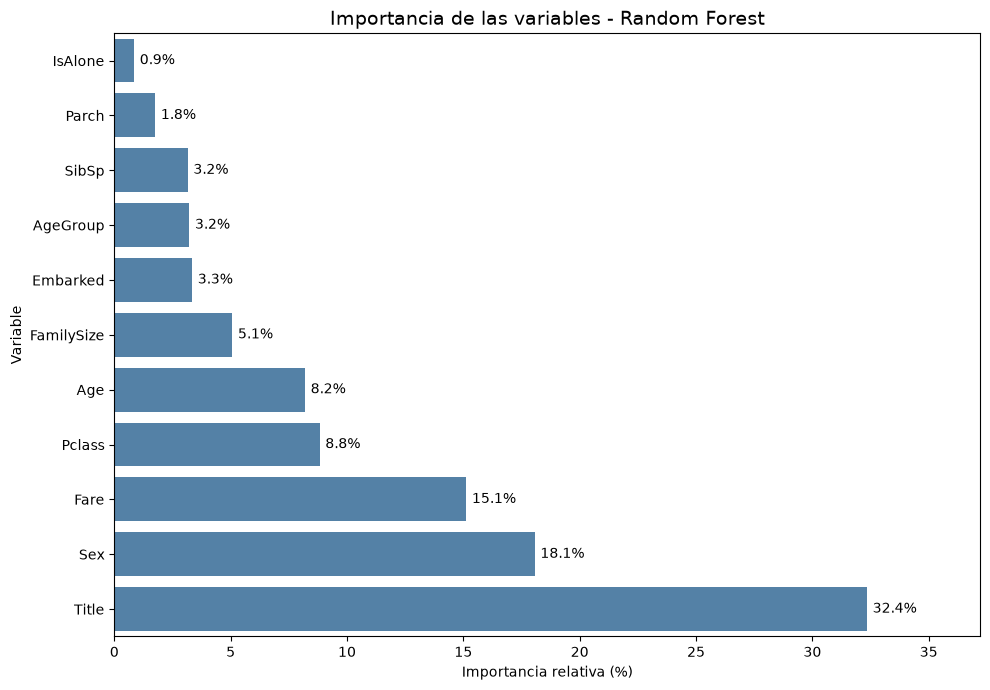

In [120]:
# Obtener los nombres de las variables y sus importancias
feature_names = preprocessor.get_feature_names_out()
feature_importances = random_forest.feature_importances_ * 100

importance_df = pd.DataFrame({
    'Variable': feature_names,
    'Importancia (%)': feature_importances
})

# Limpiar los prefijos introducidos por ColumnTransformer
importance_df['Variable'] = (
    importance_df['Variable']
    .str.replace('cat__', '', regex=False)
    .str.replace('remainder__', '', regex=False)
)

# Agrupar las categorías One-Hot Encoding bajo su variable original
categorical_variables = ['AgeGroup', 'Embarked', 'Title']

for variable in categorical_variables:
    mask = importance_df['Variable'].str.startswith(variable + '_')
    importance_df.loc[mask, 'Variable'] = variable

# Sumar las importancias de las categorías agrupadas
importance_by_variable = (
    importance_df
    .groupby('Variable')['Importancia (%)']
    .sum()
    .sort_values(ascending=True)
)

# Representación gráfica
plt.figure(figsize=(10, 7))

ax = sns.barplot(
    x=importance_by_variable.values,
    y=importance_by_variable.index,
    color='steelblue'
)

ax.bar_label(
    ax.containers[0],
    fmt='%.1f%%',
    padding=4
)

plt.title('Importancia de las variables - Random Forest', fontsize=14)
plt.xlabel('Importancia relativa (%)')
plt.ylabel('Variable')
plt.xlim(0, importance_by_variable.max() * 1.15)
plt.tight_layout()
plt.show()


Al analizar la importancia de las variables, destaca especialmente **Title**, que presenta una importancia considerablemente superior a la del resto de variables.

Este resultado es especialmente interesante porque `Title` es una variable que hemos creado durante la fase de *Feature Engineering*, extrayendo el tratamiento o título de cada pasajero a partir de su nombre (Mr, Mrs, Miss, Master, Rare, etc.).

Esto sugiere que esta transformación ha permitido al modelo aprovechar información relevante que no estaba representada de forma tan explícita en las variables originales. Por ejemplo, los títulos pueden aportar información indirecta sobre características de los pasajeros, como su edad, sexo o posición social.

### Comparación del rendimiento con y sin Feature Engineering

La creación de nuevas variables puede ayudar a los modelos de Machine Learning a identificar patrones que no resultan tan evidentes utilizando únicamente las variables originales.

Sin embargo, añadir variables no garantiza necesariamente una mejora en las predicciones. Algunas pueden aportar información útil, mientras que otras pueden introducir redundancia o incluso dificultar el aprendizaje del modelo.

Para comprobarlo, entrenaremos dos versiones de Random Forest:

1. Un modelo que utiliza únicamente las variables originales.
2. Un modelo que incorpora las variables adicionales creadas durante la fase de Feature Engineering.

Mantendremos la misma configuración de hiperparámetros y utilizaremos la misma partición de entrenamiento y validación. De esta forma, podremos atribuir las posibles diferencias de rendimiento a la incorporación de las nuevas variables.

In [122]:
from sklearn.base import clone


# Variables originales
original_features = [
    'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked'
]

# Variables creadas mediante Feature Engineering
engineered_features = [
    'FamilySize', 'IsAlone', 'AgeGroup', 'Title'
]

# Configuraciones de ambos modelos
feature_configurations = {
    'Sin Feature Engineering': {
        'features': original_features,
        'categorical': ['Embarked']
    },
    'Con Feature Engineering': {
        'features': original_features + engineered_features,
        'categorical': ['Embarked', 'AgeGroup', 'Title']
    }
}

comparison_results = []

for model_name, configuration in feature_configurations.items():

    # Seleccionar las variables correspondientes
    X_train_model = X_train[configuration['features']].copy()
    X_val_model = X_val[configuration['features']].copy()

    # Crear el preprocesador
    model_preprocessor = ColumnTransformer(
        transformers=[
            (
                'cat',
                OneHotEncoder(handle_unknown='ignore'),
                configuration['categorical']
            )
        ],
        remainder='passthrough'
    )

    # Ajustar el preprocesador únicamente con entrenamiento
    X_train_model_processed = model_preprocessor.fit_transform(X_train_model)
    X_val_model_processed = model_preprocessor.transform(X_val_model)

    # Crear y entrenar un Random Forest con los mismos hiperparámetros
    model = clone(random_forest)
    model.fit(X_train_model_processed, y_train)

    # Predicciones sobre validación
    predictions = model.predict(X_val_model_processed)

    # Calcular métricas
    report = classification_report(
        y_val,
        predictions,
        output_dict=True,
        zero_division=0
    )

    metrics = {
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision - No sobrevivió': report['0']['precision'],
        'Recall - No sobrevivió': report['0']['recall'],
        'F1-score - No sobrevivió': report['0']['f1-score'],
        'Precision - Sobrevivió': report['1']['precision'],
        'Recall - Sobrevivió': report['1']['recall'],
        'F1-score - Sobrevivió': report['1']['f1-score'],
        'F1-score - Macro avg': report['macro avg']['f1-score']
    }

    for metric_name, value in metrics.items():
        comparison_results.append({
            'Configuración': model_name,
            'Métrica': metric_name,
            'Valor': value
        })

# Guardar los resultados en un DataFrame
comparison_df = pd.DataFrame(comparison_results)

comparison_df.pivot(
    index='Métrica',
    columns='Configuración',
    values='Valor'
).round(3)


Configuración,Con Feature Engineering,Sin Feature Engineering
Métrica,,
Accuracy,0.838,0.810
F1-score - Macro avg,0.823,0.792
F1-score - No sobrevivió,0.874,0.853
F1-score - Sobrevivió,0.772,0.730
Precision - No sobrevivió,0.835,0.811
Precision - Sobrevivió,0.845,0.807
Recall - No sobrevivió,0.918,0.900
Recall - Sobrevivió,0.710,0.667


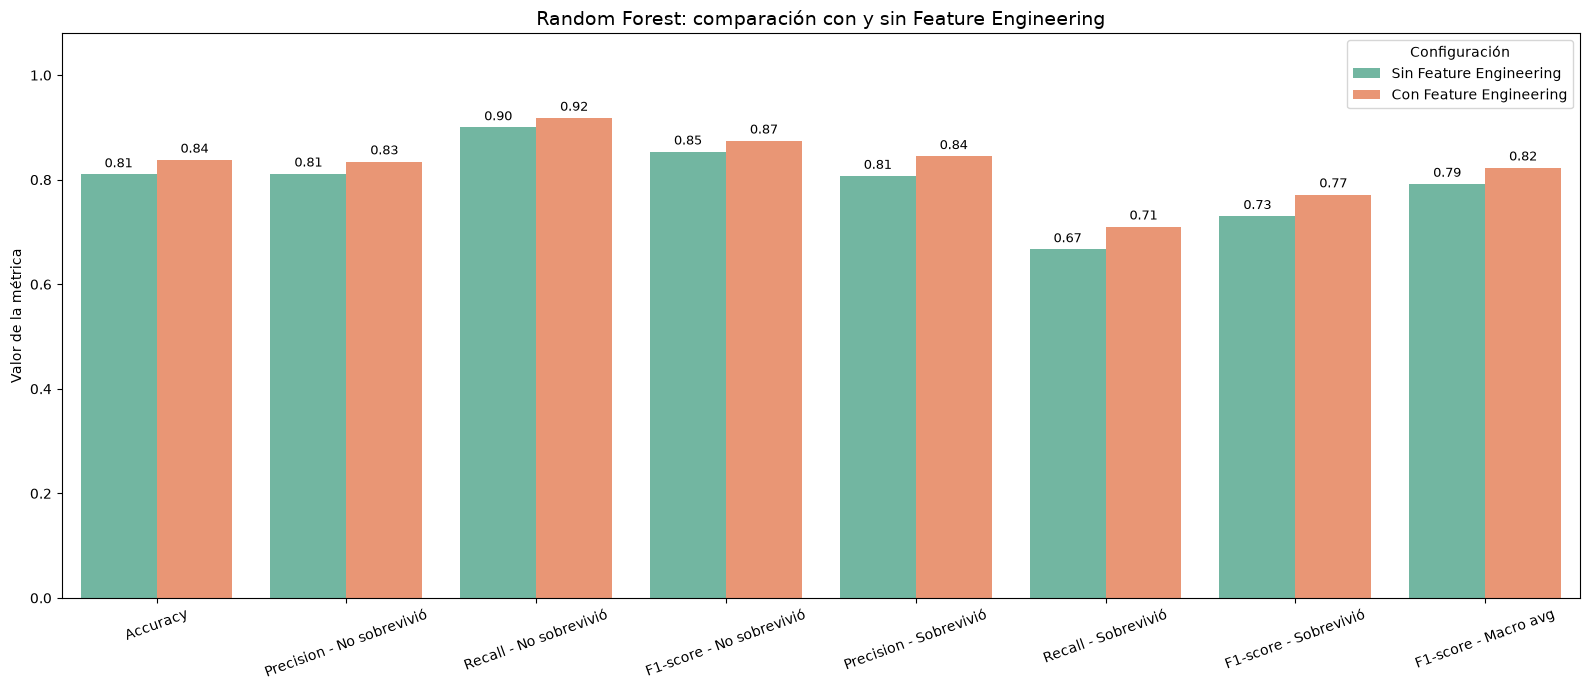

In [123]:

metric_order = [
    'Accuracy',
    'Precision - No sobrevivió',
    'Recall - No sobrevivió',
    'F1-score - No sobrevivió',
    'Precision - Sobrevivió',
    'Recall - Sobrevivió',
    'F1-score - Sobrevivió',
    'F1-score - Macro avg'
]

plt.figure(figsize=(16, 7))

ax = sns.barplot(
    data=comparison_df,
    x='Métrica',
    y='Valor',
    hue='Configuración',
    order=metric_order,
    palette='Set2',
    errorbar=None
)

ax.set_title(
    'Random Forest: comparación con y sin Feature Engineering',
    fontsize=14
)
ax.set_xlabel('')
ax.set_ylabel('Valor de la métrica')
ax.set_ylim(0, 1.08)
ax.tick_params(axis='x', rotation=20)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3, fontsize=9)

ax.legend(title='Configuración')
plt.tight_layout()
plt.show()


Como podemos observar en las gráficas, **la incorporación de las variables creadas mediante Feature Engineering mejora todas las métricas evaluadas** respecto al modelo que utiliza únicamente las variables originales.

La mejora se aprecia tanto en el rendimiento global (*Accuracy* y *F1-score macro*) como en las métricas individuales de ambas clases. Esto indica que las nuevas variables no solo ayudan al modelo a realizar más predicciones correctas, sino que también mejoran su capacidad para identificar tanto a los pasajeros que sobrevivieron como a los que no.

Este resultado pone de manifiesto la importancia de la ingeniería de características: transformar y combinar la información disponible puede ayudar a los algoritmos a identificar patrones que, de otro modo, podrían pasar desapercibidos.